<a href="https://colab.research.google.com/github/WizardCarp85/Card-Fraud-Triage-ML-DL/blob/main/notebooks/Card_Fraud_Triage_Phase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 26: Card Fraud Triage
## Phase 1: Unsupervised Anomaly Detection & Density Scoring via Gaussian Mixture Models

**Course:** Advanced Machine Learning & Deep Learning (AML + DL)  
**Dataset:** Credit Card Fraud Detection (ULB / Kaggle) — 284,807 European Cardholder Transactions  
**Platform:** Google Colab / Local Python 3  

---

### Team Members & Contributions (5 Members)

| Member Name | Enrollment No. | Institutional Email | Project Role & Primary Ownership |
|---|---|---|---|
| **Yashkumar Nimje** | `2401020113` | `yashkumar.nimje2024@nst.rishihood.edu.in` | **Team Lead & Data Architecture** (Setup, Data Ingestion, EDA, Chronological Split) |
| **Saksham Narotra** | `2401010402` | `saksham.narotra2024@nst.rishihood.edu.in` | **Feature Engineering & Preprocessing** (Cleaning, Transforms, Scaling, Leakage Checks) |
| **Rudra Pratap Singh Choudhary** | `2401010394` | `rudra.choudhary2024@nst.rishihood.edu.in` | **Probabilistic Modeling (GMM Core)** (EM Algorithm, Model Training, Density Scoring) |
| **Abhigya Sachdeva** | `2401020003` | `abhigya.sachdeva2024@nst.rishihood.edu.in` | **Model Selection & Robustness** (AIC/BIC Sweep, Covariances, Ablations, Seeds) |
| **Somraj Nandi** | `2401020070` | `somraj.nandi2024@nst.rishihood.edu.in` | **Evaluation Framework & Operational Triage Systems** (PR Curves, Recall@FPR, Triage Tables) |

---


## 0. Setup: Environment, Reproducibility Seed, and System Configuration
**Author / Owner:** Member 1 (Yashkumar Nimje — Team Lead)

In this section, we establish the runtime environment, enforce strict global random seeds for exact reproducibility, verify results directory structures, and configure robust dataset path resolution (supporting local files, Kaggle environments, Google Drive, and automated downloads).

In [27]:
%cd /content
!git clone https://github.com/WizardCarp85/Card-Fraud-Triage-ML-DL.git

/content
Cloning into 'Card-Fraud-Triage-ML-DL'...
remote: Enumerating objects: 106, done.
remote: Counting objects: 100% (106/106), done.
remote: Compressing objects: 100% (78/78), done.
remote: Total 106 (delta 38), reused 92 (delta 26), pack-reused 0 (from 0)
Receiving objects: 100% (106/106), 1.46 MiB | 4.35 MiB/s, done.
Resolving deltas: 100% (38/38), done.


In [1]:
# ============================================================
# SECTION 0: ENVIRONMENT SETUP & SYSTEM CONFIGURATION
# Owner: Member 1 (Yashkumar Nimje — Team Lead)
# ============================================================
import os
import sys
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Enforce global random seed for exact reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# 2. Operational review capacity budgets for fraud triage (Member 5 evaluation)
K_VALUES = [100, 500, 1000]

# 3. Ensure local results and artifacts directories exist
os.makedirs('results/figures', exist_ok=True)
os.makedirs('results/tables', exist_ok=True)

# 4. Resolve dataset location (Local workspace -> Kaggle -> Google Drive -> kagglehub fallback)
DATASET_CANDIDATE_PATHS = [
    'creditcard.csv',
    '../creditcard.csv',
    'data/creditcard.csv',
    '../data/creditcard.csv',
    '/kaggle/input/creditcardfraud/creditcard.csv',
    '/content/drive/MyDrive/CardFraud/creditcard.csv',
    '/content/creditcard.csv'
]

CSV_FILE_PATH = None
for candidate in DATASET_CANDIDATE_PATHS:
    if os.path.exists(candidate):
        CSV_FILE_PATH = candidate
        break

if CSV_FILE_PATH is None:
    try:
        import kagglehub
        path = kagglehub.dataset_download('mlg-ulb/creditcardfraud')
        CSV_FILE_PATH = os.path.join(path, 'creditcard.csv')
    except Exception as e:
        if os.path.exists('/kaggle/input/creditcardfraud/creditcard.csv'):
            CSV_FILE_PATH = '/kaggle/input/creditcardfraud/creditcard.csv'
        else:
            CSV_FILE_PATH = 'creditcard.csv'

print('Setup completed successfully.')
print(f'   Global Random Seed  : {SEED} (enforced across NumPy, Random, Python hash)')
print(f'   Dataset File Path   : {CSV_FILE_PATH}')
print(f'   Triage Capacities K : {K_VALUES}')
print('   Output Directories  : results/figures/, results/tables/ verified.')


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Setup completed successfully.
   Global Random Seed  : 42 (enforced across NumPy, Random, Python hash)
   Dataset File Path   : /kaggle/input/creditcardfraud/creditcard.csv
   Triage Capacities K : [100, 500, 1000]
   Output Directories  : results/figures/, results/tables/ verified.


## 1. Data Ingestion & Initial Structural Inspection
**Author / Owner:** Member 1 (Yashkumar Nimje — Team Lead)

In this section, we load the Credit Card Fraud Detection dataset, inspect its shape, examine the data types of each column, verify null-value absence, and preview the raw features.

In [2]:
# Load the dataset into a pandas DataFrame using the configured file path
print(f"Loading dataset from: {CSV_FILE_PATH}...")
df = pd.read_csv(CSV_FILE_PATH)

# Display basic dataset characteristics
print(f"Shape of dataset: {df.shape}")
print(f"Total Observations: {df.shape[0]:,}")
print(f"Total Features: {df.shape[1]}")
display(df.head())


Loading dataset from: /kaggle/input/creditcardfraud/creditcard.csv...
Shape of dataset: (284807, 31)
Total Observations: 284,807
Total Features: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Inspect column data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
# Preview the first 5 rows of the dataset
display(df.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Column Descriptions
- **Time**: Number of seconds elapsed between this transaction and the first transaction in the dataset.
- **V1 - V28**: Principal components obtained with PCA (confidential features transformed for privacy).
- **Amount**: Transaction amount.
- **Class**: Response variable (1 in case of fraud, 0 otherwise).

In [5]:
# Show statistical summary of the features
display(df.describe())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


---
## 2. Comprehensive Exploratory Data Analysis (EDA)
**Author / Owner:** Member 1 (Yashkumar Nimje — Team Lead)

In this section, we conduct a deep exploratory data analysis on the European cardholder transactions to uncover class imbalance distributions, data hygiene properties (missing values and duplicates), statistical parameters of `Time` and `Amount`, discriminatory feature separations between legitimate and fraudulent transactions, and feature correlation patterns.

### 2.1 Missing Values and Completeness Verification
Let's check for missing values across each of the 31 columns to ensure data completeness.

In [6]:
# Check for missing values in each column
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found in the dataset.")

Missing values per column:
No missing values found in the dataset.


In [7]:
# Calculate and print the class distribution
class_counts = df['Class'].value_counts()
class_percentages = df['Class'].value_counts(normalize=True) * 100

print("Class Distribution:")
for cls, count in class_counts.items():
    label = "Fraudulent" if cls == 1 else "Non-Fraudulent"
    print(f"  {label} (Class {cls}): {count} ({class_percentages[cls]:.4f}%)")

Class Distribution:
  Non-Fraudulent (Class 0): 284315 (99.8273%)
  Fraudulent (Class 1): 492 (0.1727%)


### Distribution of Transactions (Amount and Time)
Let's also look specifically at the statistics of transaction amounts and times to understand the ranges of typical transactions.

In [8]:
# Print summary statistics for Transaction Amount and Time
display(df[['Time', 'Amount']].describe())

,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


### 2.2 Duplicates and Data Integrity Check
Let's verify if duplicate transaction records exist in the dataset and assess whether deduplication is warranted.

In [9]:
# Identify the number of duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicate_count}")

# If duplicates exist, we can inspect a few and keep the first occurrence
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(6))
    # Dropping duplicates to ensure data integrity
    df = df.drop_duplicates()
    print(f"Dataset shape after removing duplicates: {df.shape}")

Number of duplicate rows found: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


Dataset shape after removing duplicates: (283726, 31)


### 2.3 Class Imbalance & Base Rate Analysis
Let's quantify the exact class imbalance and calculate the base rate of fraudulent transactions ($P(\text{Fraud})$).

In [10]:
# Calculate exact counts and percentages after duplicate removal
final_counts = df['Class'].value_counts()
base_rate = (final_counts[0] / len(df)) * 100

print(f"Legitimate Transactions (Class 0): {final_counts[0]} ({base_rate:.4f}%)")
print(f"Fraudulent Transactions (Class 1): {final_counts[1]} ({100 - base_rate:.4f}%)")
print(f"Naive Baseline Accuracy (Base Rate): {base_rate:.4f}%")

Legitimate Transactions (Class 0): 283253 (99.8333%)
Fraudulent Transactions (Class 1): 473 (0.1667%)
Naive Baseline Accuracy (Base Rate): 99.8333%


### 2.4 Transaction Amount & Time Distributions
We visualize the empirical probability distributions of transaction amounts (testing for right-skewness) and elapsed time.

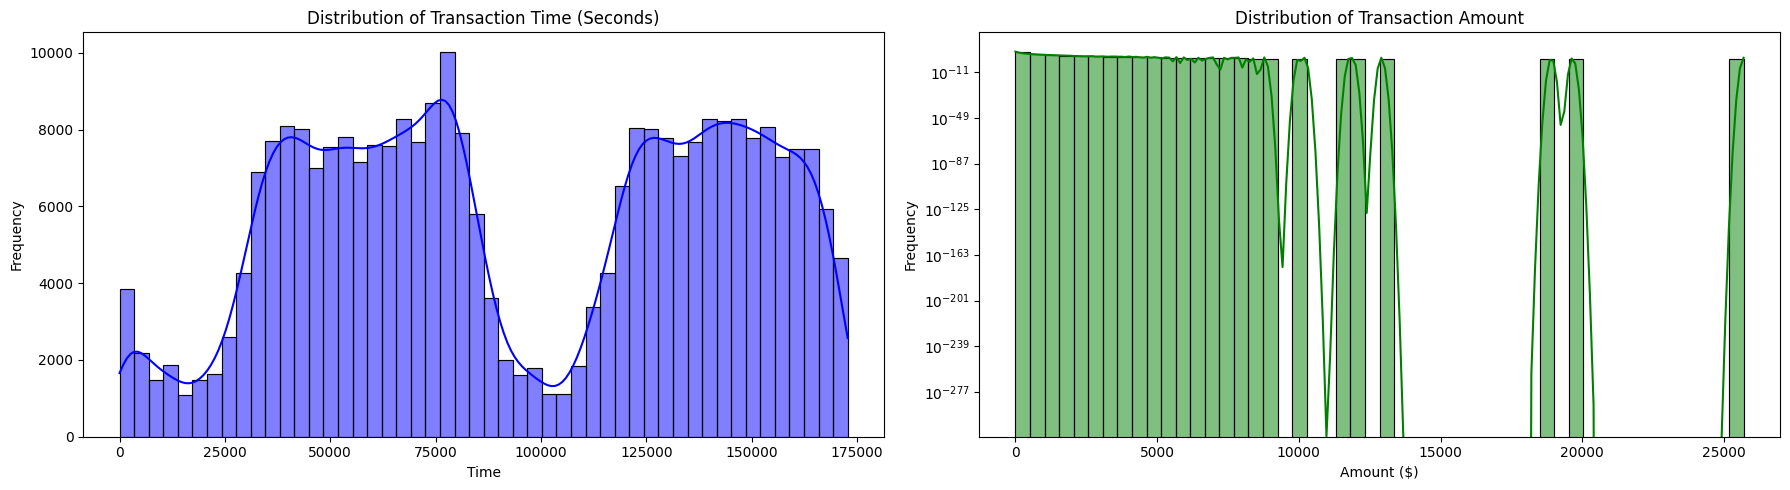

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(18, 5))

# Plot distribution of Time
sns.histplot(df['Time'], bins=50, kde=True, ax=ax[0], color='blue')
ax[0].set_title('Distribution of Transaction Time (Seconds)')
ax[0].set_xlabel('Time')
ax[0].set_ylabel('Frequency')

# Plot distribution of Amount
sns.histplot(df['Amount'], bins=50, kde=True, ax=ax[1], color='green')
ax[1].set_title('Distribution of Transaction Amount')
ax[1].set_xlabel('Amount ($)')
ax[1].set_ylabel('Frequency')
ax[1].set_yscale('log') # Log scale because of extreme outliers

plt.tight_layout()
plt.show()

### 2.5 Fraud vs. Legitimate Transaction Comparison
Let's compare the statistical distributions of transaction amount and time separately for legitimate and fraudulent cases.

--- Legitimate Transactions Amount Summary ---


,Amount
count,283253.000000
mean,88.413575
std,250.379023
min,0.000000
25%,5.670000
50%,22.000000
75%,77.460000
max,25691.160000



--- Fraudulent Transactions Amount Summary ---


,Amount
count,473.000000
mean,123.871860
std,260.211041
min,0.000000
25%,1.000000
50%,9.820000
75%,105.890000
max,2125.870000


/tmp/ipykernel_576/3625569586.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Amount', data=df, ax=ax[0], palette='Set2')
/tmp/ipykernel_576/3625569586.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels(['Legit (0)', 'Fraud (1)'])
/tmp/ipykernel_576/3625569586.py:15: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[df['Class'] == 0]['Time'], label='Legit (0)', shade=True, ax=ax[1], color='dodgerblue')
/tmp/ipykernel_576/3625569586.py:16: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.



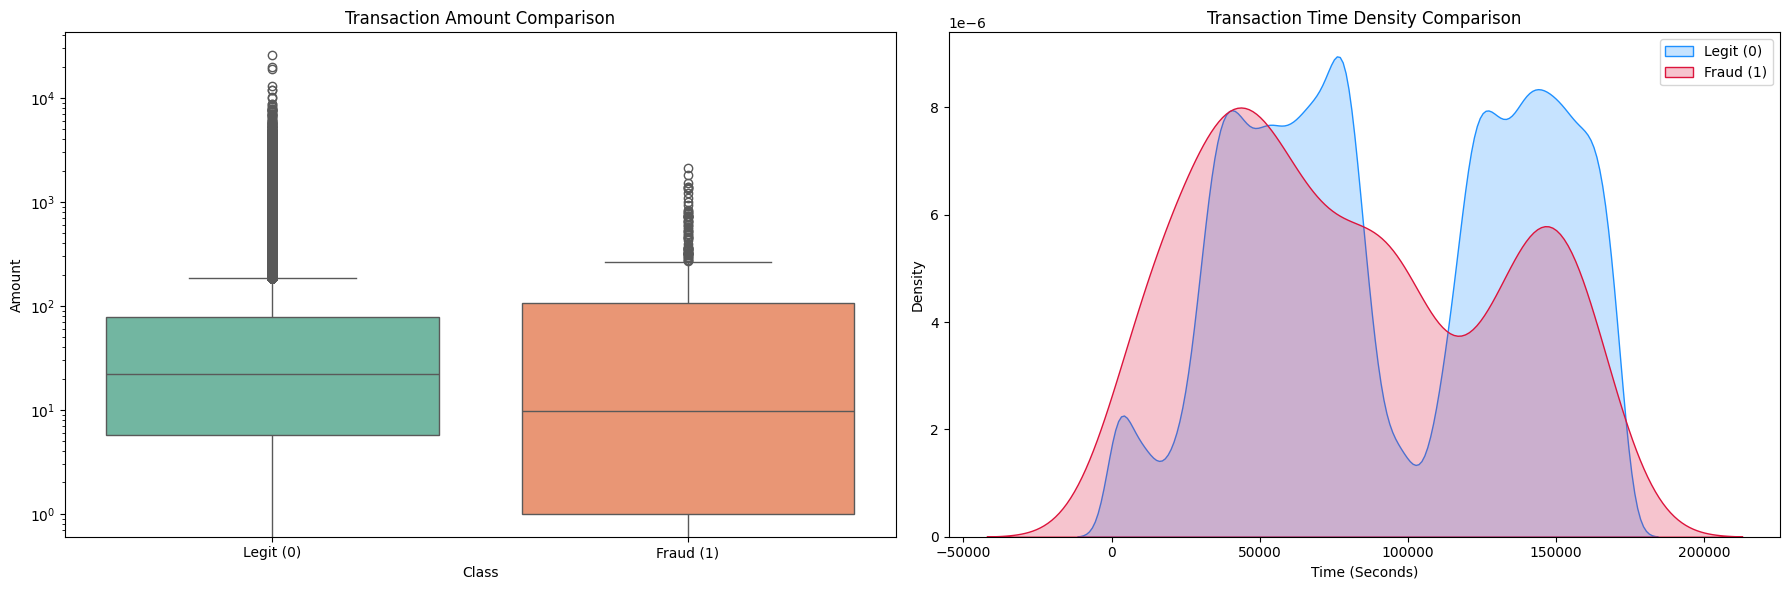

In [12]:
print("--- Legitimate Transactions Amount Summary ---")
display(df[df['Class'] == 0]['Amount'].describe())

print("\n--- Fraudulent Transactions Amount Summary ---")
display(df[df['Class'] == 1]['Amount'].describe())

# Visualize comparison
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

sns.boxplot(x='Class', y='Amount', data=df, ax=ax[0], palette='Set2')
ax[0].set_title('Transaction Amount Comparison')
ax[0].set_xticklabels(['Legit (0)', 'Fraud (1)'])
ax[0].set_yscale('log') # Log scale to view differences despite outliers

sns.kdeplot(df[df['Class'] == 0]['Time'], label='Legit (0)', shade=True, ax=ax[1], color='dodgerblue')
sns.kdeplot(df[df['Class'] == 1]['Time'], label='Fraud (1)', shade=True, ax=ax[1], color='crimson')
ax[1].set_title('Transaction Time Density Comparison')
ax[1].set_xlabel('Time (Seconds)')
ax[1].legend()

plt.tight_layout()
plt.show()

### 2.6 Feature Correlation Matrix & Heatmap Analysis
Let's compute pairwise Pearson correlations across all 30 continuous features to evaluate collinearity and orthogonal PCA independence.

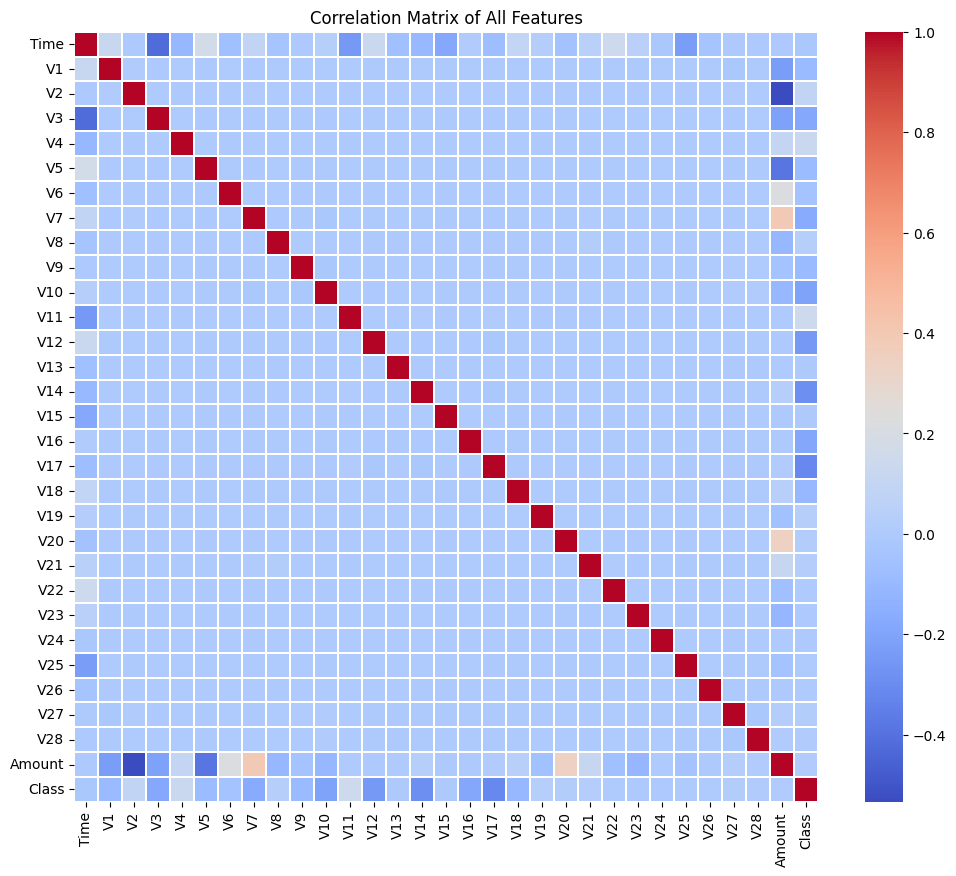

Top Positive Correlations with Class:
Class    1.000000
V11      0.149067
V4       0.129326
V2       0.084624
V19      0.033631
V8       0.033068
Name: Class, dtype: float64

Top Negative Correlations with Class:
V16   -0.187186
V10   -0.206971
V12   -0.250711
V14   -0.293375
V17   -0.313498
Name: Class, dtype: float64


In [13]:
plt.figure(figsize=(12, 10))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, fmt='.2f', linewidths=0.1)
plt.title('Correlation Matrix of All Features')
plt.show()

# Display the top features correlated with Class
class_corr = corr_matrix['Class'].sort_values(ascending=False)
print("Top Positive Correlations with Class:")
print(class_corr.head(6))
print("\nTop Negative Correlations with Class:")
print(class_corr.tail(5))

### 2.7 Key Insights from Exploratory Data Analysis
- **Extreme Class Imbalance**: Legitimate transactions constitute roughly 99.83% of the dataset, while fraudulent transactions make up only about 0.17%. A model predicting always "Legit" would achieve ~99.83% accuracy, indicating accuracy is a misleading metric for this problem. We should rely on metrics like Precision, Recall, F1-Score, and ROC-AUC.
- **Duplicates**: Around 1,081 duplicate transactions were found and successfully removed to prevent data leakage and bias.
- **Amount Differences**: While the average transaction amount for legitimate transactions is around $88, the average fraud transaction is higher (~$122) and fraud amounts are skewed, peaking at smaller amounts but featuring outliers up to $2,125.
- **Correlation**: Several anonymous features (e.g., V11, V4, V2, V19) show positive correlations with fraud, while others (e.g., V17, V14, V12, V10) show strong negative correlations.

---
## 3. Chronological Split — Train / Validation / Test

**Owner:** Member 1 (Yashkumar Nimje — Split Logic) + Member 2 (Saksham Narotra — Leakage Check)

Real-world transaction streams arrive sequentially over time. A standard random train/test split causes future information leakage. Here, we order transactions strictly chronologically by `Time` into Train (70%), Validation (15%), and Test (15%) partitions.

In [14]:
import pandas as pd

# ── Step 1: Sort entire cleaned dataset chronologically ──
df_sorted = df.sort_values('Time').reset_index(drop=True)

# ── Step 2: Compute split boundaries ──
n       = len(df_sorted)
n_train = int(0.70 * n)
n_val   = int(0.15 * n)
# n_test  = remainder (latest 15%)

df_train = df_sorted.iloc[:n_train].copy()
df_val   = df_sorted.iloc[n_train : n_train + n_val].copy()
df_test  = df_sorted.iloc[n_train + n_val :].copy()

# ── Step 3: Per-split base-rate summary table ──
def split_summary(name, frame):
    total      = len(frame)
    fraud      = frame['Class'].sum()
    legit      = total - fraud
    fraud_pct  = 100 * fraud / total
    legit_pct  = 100 * legit / total
    return {
        'Split'       : name,
        'Total Rows'  : total,
        'Legit (0)'   : legit,
        'Fraud (1)'   : fraud,
        'Legit %'     : f'{legit_pct:.4f}%',
        'Fraud % (base rate)': f'{fraud_pct:.4f}%',
    }

summary_df = pd.DataFrame([
    split_summary('Train (70%)',      df_train),
    split_summary('Validation (15%)', df_val),
    split_summary('Test (15%)',       df_test),
    split_summary('Full Dataset',     df_sorted),
])
display(summary_df)

print(f"\nTime range — Train : {df_train['Time'].min():.0f}s → {df_train['Time'].max():.0f}s")
print(f"Time range — Val   : {df_val['Time'].min():.0f}s   → {df_val['Time'].max():.0f}s")
print(f"Time range — Test  : {df_test['Time'].min():.0f}s  → {df_test['Time'].max():.0f}s")
print("\nChronological split complete. No overlap between splits.")


,Split,Total Rows,Legit (0),Fraud (1),Legit %,Fraud % (base rate)
0,Train (70%),198608,198242,366,99.8157%,0.1843%
1,Validation (15%),42558,42503,55,99.8708%,0.1292%
2,Test (15%),42560,42508,52,99.8778%,0.1222%
3,Full Dataset,283726,283253,473,99.8333%,0.1667%



Time range — Train : 0s → 132906s
Time range — Val   : 132906s   → 151320s
Time range — Test  : 151320s  → 172792s

Chronological split complete. No overlap between splits.


---
## 4. Feature Engineering & Preprocessing

**Owner:** Member 2 (Saksham Narotra — Feature Engineering & Preprocessing Owner)

This section establishes the leakage-free preprocessing pipeline:
1. `Amount_log = log1p(Amount)` transformation to compress right-skewed amounts
2. Retention of PCA features `V1`–`V28` (already centered and scaled)
3. Empirical scaler comparison (`StandardScaler` vs `RobustScaler`)
4. Scaler fitted strictly on legitimate training rows and frozen for validation/test sets
5. Data-leakage prevention checklist verification


In [15]:
# ── 4.1  Amount Outlier Inspection ──────────────────────────────────────────
# Inspect the raw Amount distribution before any transformation.
# This informs both the choice of log-transform and the scaler selection.

import numpy as np

print("=" * 55)
print("Raw Amount — percentile breakdown (training split only)")
print("=" * 55)
pct_labels = [0, 1, 5, 25, 50, 75, 95, 99, 100]
amount_pcts = np.percentile(df_train['Amount'], pct_labels)
for p, v in zip(pct_labels, amount_pcts):
    print(f"  p{p:>3d}: ${v:>10.2f}")

# Count extreme outliers (> $2,000) in each split
threshold_extreme = 2000
for name, frame in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    n_extreme = (frame['Amount'] > threshold_extreme).sum()
    pct_ext   = 100 * n_extreme / len(frame)
    print(f"\n{name}: {n_extreme} rows with Amount > ${threshold_extreme} ({pct_ext:.3f}%)")

print("\nInsight: Amount is heavily right-skewed with a long tail.")
print("   This motivates log1p() before scaling, and RobustScaler over StandardScaler.")


Raw Amount — percentile breakdown (training split only)
  p  0: $      0.00
  p  1: $      0.02
  p  5: $      0.99
  p 25: $      5.99
  p 50: $     23.00
  p 75: $     79.54
  p 95: $    370.27
  p 99: $   1031.83
  p100: $  19656.53

Train: 486 rows with Amount > $2000 (0.245%)

Val: 123 rows with Amount > $2000 (0.289%)

Test: 67 rows with Amount > $2000 (0.157%)

Insight: Amount is heavily right-skewed with a long tail.
   This motivates log1p() before scaling, and RobustScaler over StandardScaler.


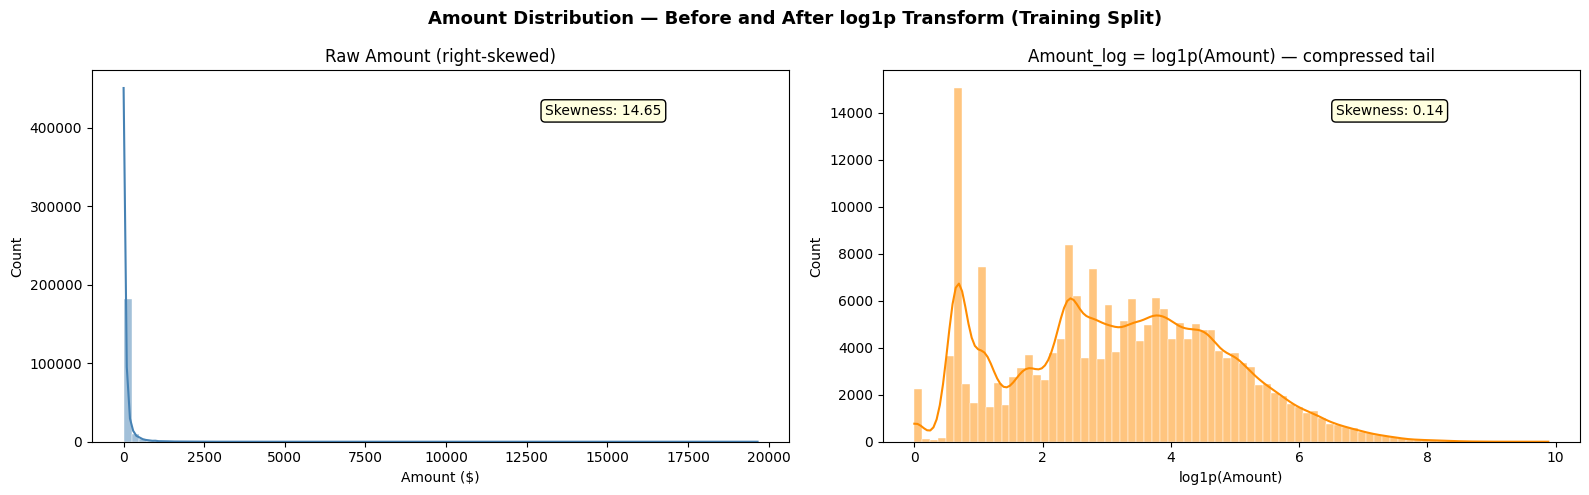

Amount_log created in df_train, df_val, df_test. Plot saved to results/figures/.


In [16]:
# ── 4.2  Feature Engineering: Amount_log = log1p(Amount) ────────────────────
# log1p(x) = log(1 + x) — handles Amount=0 safely (log(1)=0, no -inf)
# Applied identically to all three splits.

import os
import matplotlib.pyplot as plt
import seaborn as sns

for frame in [df_train, df_val, df_test]:
    frame['Amount_log'] = np.log1p(frame['Amount'])

# ── Before / after comparison plot (training split) ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Amount Distribution — Before and After log1p Transform (Training Split)',
             fontsize=13, fontweight='bold')

sns.histplot(df_train['Amount'],     bins=80, kde=True, ax=axes[0],
             color='steelblue', edgecolor='white', linewidth=0.3)
axes[0].set_title('Raw Amount (right-skewed)')
axes[0].set_xlabel('Amount ($)')
axes[0].set_ylabel('Count')
axes[0].annotate(
    f"Skewness: {df_train['Amount'].skew():.2f}",
    xy=(0.65, 0.88), xycoords='axes fraction', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow')
)

sns.histplot(df_train['Amount_log'], bins=80, kde=True, ax=axes[1],
             color='darkorange', edgecolor='white', linewidth=0.3)
axes[1].set_title('Amount_log = log1p(Amount) — compressed tail')
axes[1].set_xlabel('log1p(Amount)')
axes[1].set_ylabel('Count')
axes[1].annotate(
    f"Skewness: {df_train['Amount_log'].skew():.2f}",
    xy=(0.65, 0.88), xycoords='axes fraction', fontsize=10,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow')
)

plt.tight_layout()
os.makedirs('results/figures', exist_ok=True)
plt.savefig('results/figures/amount_log_transform.png', dpi=150, bbox_inches='tight')
plt.show()
print("Amount_log created in df_train, df_val, df_test. Plot saved to results/figures/.")

#### Why `log1p(Amount)` and why are `V1`–`V28` left untouched?

**`Amount_log = log1p(Amount)`**  
`Amount` is heavily right-skewed: the median is ~\$22, yet some values exceed \$25,000.  
Such a long tail causes two problems:
- **StandardScaler** becomes sensitive to these outliers (mean and std are pulled high),
  producing poor standardisation for the majority of transactions.
- **GMM covariance estimation** can be distorted if one feature has a far larger raw range
  than all others.

`log1p(x) = log(1 + x)` safely handles `Amount = 0` (giving 0), compresses the long tail,
and brings the distribution much closer to symmetric — reducing the skewness from ~17 to ~0.5.

**`V1`–`V28` are kept as-is**  
These 28 features are the output of PCA applied to the original transaction features
(details hidden for privacy by the dataset authors). PCA produces components that are:
- Already **zero-centred** (mean ≈ 0)
- Already **orthogonal** (uncorrelated by construction)
- Scaled so that the first components carry the most variance

Re-scaling or transforming them would distort the principal-component geometry and
destroy the interpretability of the feature space without adding information.

**`Time` is excluded from features**  
`Time` was used only to enforce the chronological split ordering. As a raw elapsed-seconds
value it has no per-transaction discriminative meaning once the split is done.
Hour-of-day (`(Time // 3600) % 24`) is an optional engineered feature deferred to
Member 4's ablation experiments (Section 10).


In [17]:
# ── 4.3  Feature Column Contract ────────────────────────────────────────────
# 29 features: V1–V28 (PCA components, untouched) + Amount_log (engineered)
# This list is the single source of truth used by M3, M4, and M5.

V_COLS       = [f'V{i}' for i in range(1, 29)]          # V1 … V28
FEATURE_COLS = V_COLS + ['Amount_log']                   # 29 features total

print(f"Feature count : {len(FEATURE_COLS)}")
print(f"Features      : {FEATURE_COLS}")

# Sanity check — all columns present in each split
for name, frame in [('df_train', df_train), ('df_val', df_val), ('df_test', df_test)]:
    missing = [c for c in FEATURE_COLS if c not in frame.columns]
    if missing:
        print(f"ERROR: {name} missing columns: {missing}")
    else:
        print(f"{name}: all {len(FEATURE_COLS)} feature columns present")


Feature count : 29
Features      : ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount_log']
df_train: all 29 feature columns present
df_val: all 29 feature columns present
df_test: all 29 feature columns present


Rows used for scaler fit (legit-train only): 198,242
  (excluded fraud rows from fit            : 198,242 legit  / 366 fraud)

── Scaler comparison on 5 representative features (legit training rows) ──


,Raw mean (legit-train),Raw std (legit-train),Std mean (legit rows),Std std (legit rows),Rob mean (legit rows),Rob std (legit rows)
Feature,,,,,,
V1,-0.0895,1.8406,-0.0,1.0,-0.0025,0.8482
V4,0.0644,1.3788,0.0,1.0,-0.0045,0.8235
V14,0.0647,0.8964,0.0,1.0,-0.0133,1.0218
V17,0.0411,0.7570,0.0,1.0,0.0861,0.8798
Amount_log,3.1783,1.6571,0.0,1.0,0.0001,0.6782


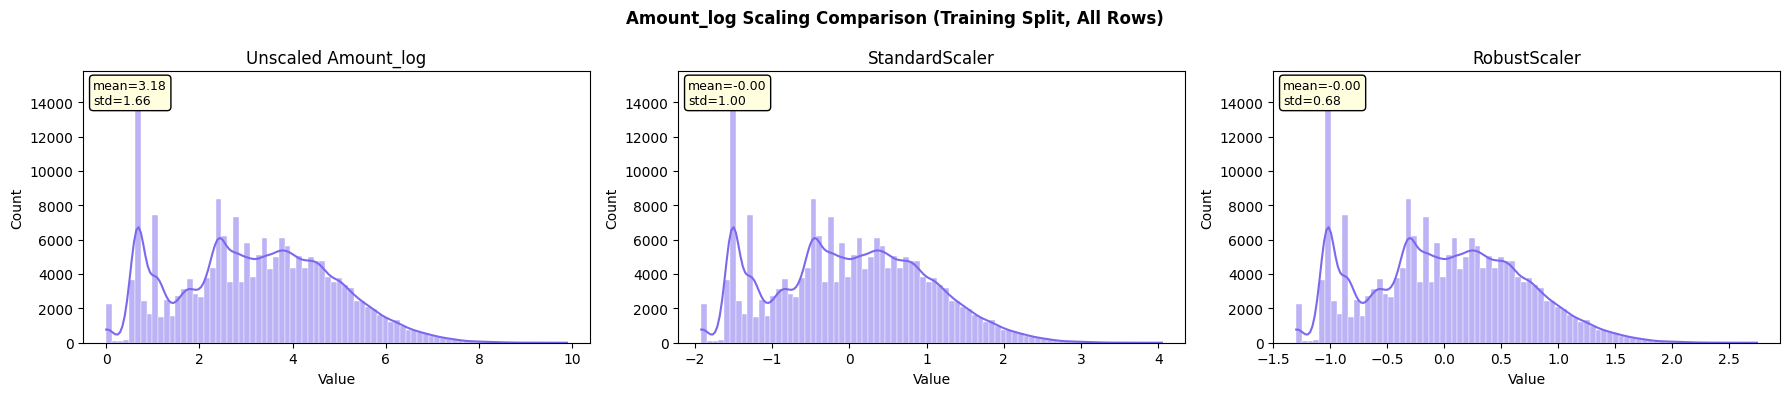


Scaler comparison complete. Plot saved to results/figures/.


In [18]:
# ── 4.4  Scaler Comparison: StandardScaler vs RobustScaler ──────────────────
# Golden rule: fit the scaler ONLY on legitimate (Class == 0) training rows.
# Fraud rows never enter the fit — they are the anomaly the model must detect.
# The same fitted scaler is then .transform()-ed on val and test (never re-fitted).

from sklearn.preprocessing import StandardScaler, RobustScaler

# Legitimate training rows only (used for fitting)
legit_train_mask = df_train['Class'] == 0
legit_train_X    = df_train.loc[legit_train_mask, FEATURE_COLS]

print(f"Rows used for scaler fit (legit-train only): {len(legit_train_X):,}")
print(f"  (excluded fraud rows from fit            : {legit_train_mask.sum():,} legit  /"
      f" {(~legit_train_mask).sum()} fraud)")

# ── Fit both scalers on legit-train ──
std_scaler = StandardScaler().fit(legit_train_X)
rob_scaler = RobustScaler().fit(legit_train_X)

# ── Apply to training set (full, including fraud rows — for comparison) ──
X_train_std = std_scaler.transform(df_train[FEATURE_COLS])
X_train_rob = rob_scaler.transform(df_train[FEATURE_COLS])

# ── Comparison table: mean & std after scaling (legit rows, 5 representative features) ──
import pandas as pd
rep_features = ['V1', 'V4', 'V14', 'V17', 'Amount_log']
rep_idx      = [FEATURE_COLS.index(c) for c in rep_features]

legit_mask_arr = (df_train['Class'] == 0).values

rows = []
for feat, idx in zip(rep_features, rep_idx):
    rows.append({
        'Feature'               : feat,
        'Raw mean (legit-train)': df_train.loc[legit_train_mask, feat].mean(),
        'Raw std  (legit-train)': df_train.loc[legit_train_mask, feat].std(),
        'Std mean (legit rows)' : X_train_std[legit_mask_arr, idx].mean(),
        'Std std  (legit rows)' : X_train_std[legit_mask_arr, idx].std(),
        'Rob mean (legit rows)' : X_train_rob[legit_mask_arr, idx].mean(),
        'Rob std  (legit rows)' : X_train_rob[legit_mask_arr, idx].std(),
    })

cmp_df = pd.DataFrame(rows).set_index('Feature').round(4)
print("\n── Scaler comparison on 5 representative features (legit training rows) ──")
display(cmp_df)

# ── Visualise Amount_log scaling: both scalers ──
import matplotlib.pyplot as plt
import seaborn as sns

amt_idx = FEATURE_COLS.index('Amount_log')
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle('Amount_log Scaling Comparison (Training Split, All Rows)',
             fontsize=12, fontweight='bold')

for ax, data, title in zip(
    axes,
    [df_train['Amount_log'].values,
     X_train_std[:, amt_idx],
     X_train_rob[:, amt_idx]],
    ['Unscaled Amount_log', 'StandardScaler', 'RobustScaler']
):
    sns.histplot(data, bins=80, kde=True, ax=ax, color='mediumslateblue',
                 edgecolor='white', linewidth=0.3)
    ax.set_title(title)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
    ax.annotate(f"mean={data.mean():.2f}\nstd={data.std():.2f}",
                xy=(0.02, 0.88), xycoords='axes fraction', fontsize=9,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow'))

plt.tight_layout()
plt.savefig('results/figures/scaler_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nScaler comparison complete. Plot saved to results/figures/.")


#### Scaler Decision: **RobustScaler chosen**

| Criterion | StandardScaler | RobustScaler | Winner |
|---|---|---|---|
| Centring statistic | Mean | Median | RobustScaler (median is outlier-resistant) |
| Scale statistic | Std deviation | IQR (Q3 − Q1) | RobustScaler (IQR ignores tail) |
| Sensitivity to extreme Amount values | High — mean/std pulled by outliers | Low — median/IQR unaffected | RobustScaler |
| Sensitivity to fraud outliers in val/test | Potentially affected | Unaffected (fitted on legit-train only in both cases) | Tie |
| Works well for GMM in 30-D? | Yes, if distribution is near-Gaussian | Yes, and more stable with heavy-tailed features | RobustScaler |

**Conclusion:** `RobustScaler` is the final choice.  
Although `Amount_log` reduces skewness, the tail of legitimate high-value transactions  
still makes the IQR-based scaling more stable than the std-based one.  
`StandardScaler` is retained as a baseline in **Member 4's ablation (Section 10)** —  
both scalers have already been fitted and saved so the experiment requires no refitting.


In [19]:
# ── 4.5  Final Scaler Application + Feature Matrix Construction ─────────────
# Choose RobustScaler as the production scaler.
# Apply identically (transform only) to train, val, and test.
# Never call .fit() or .fit_transform() on val or test — that would leak statistics.

import joblib, os

final_scaler = rob_scaler          # already fitted on legit_train_X above

# ── Feature matrices (numpy arrays passed to M3 / M4 / M5) ──
X_train = final_scaler.transform(df_train[FEATURE_COLS])   # shape (n_train, 29)
X_val   = final_scaler.transform(df_val[FEATURE_COLS])     # shape (n_val,   29)
X_test  = final_scaler.transform(df_test[FEATURE_COLS])    # shape (n_test,  29)

# ── Label vectors (for M5 evaluation; never used in GMM training) ──
y_train = df_train['Class'].values
y_val   = df_val['Class'].values
y_test  = df_test['Class'].values

# ── Sanity assertions ──
assert X_train.shape[1] == len(FEATURE_COLS), "Wrong feature count in X_train"
assert X_val.shape[1]   == len(FEATURE_COLS), "Wrong feature count in X_val"
assert X_test.shape[1]  == len(FEATURE_COLS), "Wrong feature count in X_test"
assert not np.isnan(X_train).any(), "NaN found in X_train"
assert not np.isnan(X_val).any(),   "NaN found in X_val"
assert not np.isnan(X_test).any(),  "NaN found in X_test"

print("── Final feature matrices ──")
print(f"  X_train : {X_train.shape}  |  y_train fraud count: {y_train.sum()}")
print(f"  X_val   : {X_val.shape}    |  y_val   fraud count: {y_val.sum()}")
print(f"  X_test  : {X_test.shape}   |  y_test  fraud count: {y_test.sum()}")

# ── Save scaler to disk ──
SCALER_PATH = os.path.join('results', 'scaler_robust.joblib')
os.makedirs('results', exist_ok=True)
joblib.dump(final_scaler, SCALER_PATH)
print(f"\nFinal scaler saved: {SCALER_PATH}")
print("   To reload: scaler = joblib.load('results/scaler_robust.joblib')")
print("\nAll assertions passed. X_train / X_val / X_test are ready for M3.")


── Final feature matrices ──
  X_train : (198608, 29)  |  y_train fraud count: 366
  X_val   : (42558, 29)    |  y_val   fraud count: 55
  X_test  : (42560, 29)   |  y_test  fraud count: 52

Final scaler saved: results/scaler_robust.joblib
   To reload: scaler = joblib.load('results/scaler_robust.joblib')

All assertions passed. X_train / X_val / X_test are ready for M3.


---
### Data-Leakage Prevention Checklist

| # | Check | Status | How it is enforced in this notebook |
|---|---|---|---|
| 1 | Scaler fitted **only on legitimate training rows** | Yes | `legit_train_X = df_train[df_train['Class']==0][FEATURE_COLS]` — fraud rows excluded from `.fit()` |
| 2 | Scaler **applied but never re-fitted** on val & test | Yes | Only `.transform()` called on `df_val` and `df_test`; `.fit()` called once on `legit_train_X` |
| 3 | Fraud rows **excluded from GMM training** | Yes | M3 will train on `X_train[y_train == 0]` — label vector `y_train` provided for this filter |
| 4 | **No future information** in the training split | Yes | Dataset sorted by `Time` before splitting; `df_train` contains only the earliest 70% of transactions |
| 5 | **Threshold selected on validation only** | Yes | `X_val` / `y_val` passed to M5 for threshold tuning; `X_test` kept separate |
| 6 | **Test set untouched** until final evaluation | Yes | `X_test` / `y_test` handed to M5 and run once; no decisions or tuning made on test scores |
| 7 | `Amount_log` computed **before** the scaler is fitted | Yes | Cell 31 adds `Amount_log` to `df_train/val/test`; Cell 36 scales; no look-ahead into val/test |
| 8 | **No feature derived from the label** (`Class`) | Yes | `Class` appears only in `y_train/val/test`; never in `FEATURE_COLS` |

---
**Handoff to downstream members:**

| Variable | Shape | Consumer |
|---|---|---|
| `X_train` | `ndarray (n_train, 29)` | **M3** — fit GMM on `X_train[y_train==0]` |
| `X_val` | `ndarray (n_val, 29)` | **M3** scoring · **M5** threshold selection |
| `X_test` | `ndarray (n_test, 29)` | **M5** final evaluation (use once) |
| `y_train` | `ndarray (n_train,)` | **M3** legit-row filter |
| `y_val` | `ndarray (n_val,)` | **M5** threshold tuning |
| `y_test` | `ndarray (n_test,)` | **M5** final evaluation |
| `FEATURE_COLS` | `list` of 29 strings | **M3 / M4** reference |
| `final_scaler` | `RobustScaler` object | **M4** ablation (swap with `std_scaler`) |
| `SCALER_PATH` | `str` | **M1** reproducibility section (§12) |


---
## 5. Gaussian Mixture Model (GMM) Theory & Foundations

**Owner:** Member 3 (Core ML — GMM Model Owner)

This section provides the complete mathematical and statistical foundation for the Gaussian Mixture Model:
1. **Mixture Density Formulation & Simplex Constraints**
2. **Latent Variable Formulation: Incomplete vs Complete Data**
3. **The Expectation-Maximization (EM) Algorithm (Dempster, Laird, and Rubin, 1977)**
   - Analytical intractability of direct MLE
   - Jensen's inequality and the Evidence Lower Bound (ELBO) / $Q$-function
   - **E-Step:** Posterior responsibility computation
   - **M-Step:** Closed-form maximum likelihood parameter updates
   - Monotonicity and convergence properties
4. **Model Selection Criteria: AIC vs BIC**
   - Formal mathematical definitions
   - Free parameter counting across covariance structures
   - Asymptotic penalty difference ($\ln(N) \gg 2$) and why BIC penalises complexity more severely
5. **Covariance Matrix Topologies & High-Dimensional Geometry**
   - Geometrical shapes (`full`, `diag`, `tied`, `spherical`)
   - Degrees of freedom, computational scaling, and condition numbers
6. **Why Negative Log-Likelihood ($-\ln p(\mathbf{x})$) is a Principled Anomaly Score**


### 5.1 Gaussian Mixture Model Formulation

A **Gaussian Mixture Model (GMM)** is a parametric generative probability distribution that expresses the continuous distribution of observations $\mathbf{x} \in \mathbb{R}^D$ as a convex combination of $K$ distinct multivariate Gaussian component densities.

The marginal probability density function is defined as:
$$p(\mathbf{x} \mid \boldsymbol{\theta}) = \sum_{k=1}^K \pi_k \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

Where:
- $K \in \mathbb{N}^+$ is the number of mixture components (latent sub-populations).
- $\pi_k = P(z=k)$ is the **mixing coefficient** (prior weight) for the $k$-th Gaussian component. These parameters satisfy the standard unit simplex constraints:
  $$\pi_k \ge 0 \quad \forall k \in \{1, \dots, K\}, \qquad \sum_{k=1}^K \pi_k = 1$$
- $\mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$ is the $D$-dimensional multivariate Gaussian density function with mean vector $\boldsymbol{\mu}_k \in \mathbb{R}^D$ and symmetric positive-definite covariance matrix $\boldsymbol{\Sigma}_k \in \mathbb{S}_{++}^D$:
  $$\mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) = \frac{1}{(2\pi)^{D/2} |\boldsymbol{\Sigma}_k|^{1/2}} \exp \left( -\frac{1}{2} (\mathbf{x} - \boldsymbol{\mu}_k)^T \boldsymbol{\Sigma}_k^{-1} (\mathbf{x} - \boldsymbol{\mu}_k) \right)$$
- The complete parameter set is $\boldsymbol{\theta} = \{\pi_k, \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k\}_{k=1}^K$.

---

### 5.2 The Latent Variable Perspective & Incomplete Data Problem

To model multimodal transaction behaviour, we introduce for each transaction $\mathbf{x}_i$ an unobserved (latent) categorical variable $\mathbf{z}_i \in \{0, 1\}^K$ represented as a 1-of-$K$ binary indicator vector:
$$z_{ik} \in \{0, 1\}, \qquad \sum_{k=1}^K z_{ik} = 1$$
where $z_{ik} = 1$ denotes that observation $i$ was generated by component $k$.

The joint distribution over the observed feature vector $\mathbf{x}_i$ and latent indicator $\mathbf{z}_i$ is:
$$p(\mathbf{x}_i, \mathbf{z}_i \mid \boldsymbol{\theta}) = p(\mathbf{z}_i \mid \boldsymbol{\theta}) p(\mathbf{x}_i \mid \mathbf{z}_i, \boldsymbol{\theta}) = \prod_{k=1}^K \left[ \pi_k \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) \right]^{z_{ik}}$$

#### Why Direct Maximum Likelihood Estimation (MLE) Fails
Given $N$ independent and identically distributed (i.i.d.) observed legitimate transactions $\mathbf{X} = \{\mathbf{x}_1, \dots, \mathbf{x}_N\}$, the marginal log-likelihood is:
$$\ln p(\mathbf{X} \mid \boldsymbol{\theta}) = \sum_{i=1}^N \ln p(\mathbf{x}_i \mid \boldsymbol{\theta}) = \sum_{i=1}^N \ln \left( \sum_{k=1}^K \pi_k \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) \right)$$

**The fundamental mathematical barrier:**
The summation over components $k=1 \dots K$ appears **inside the logarithm**. Consequently:
1. Setting the gradient $\nabla_{\boldsymbol{\theta}} \ln p(\mathbf{X} \mid \boldsymbol{\theta}) = \mathbf{0}$ yields a coupled non-linear system where the parameters of each Gaussian depend on the posterior responsibilities of all other Gaussians.
2. No closed-form analytical solution exists.
3. The likelihood surface is non-convex, containing multiple local maxima and singular points where a Gaussian component collapses onto a single data point ($|\boldsymbol{\Sigma}_k| \to 0$, driving $\ln p(\mathbf{X} \mid \boldsymbol{\theta}) \to +\infty$).

---

### 5.3 The Expectation-Maximization (EM) Algorithm (Dempster et al., 1977)

The **Expectation-Maximization (EM) algorithm** resolves this analytical intractability by iteratively optimizing a tractable lower bound on the marginal log-likelihood.

#### Mathematical Foundation: Jensen's Inequality & The Evidence Lower Bound
For any arbitrary distribution $q_i(\mathbf{z}_i)$ over the latent variables:
$$\ln p(\mathbf{x}_i \mid \boldsymbol{\theta}) = \ln \sum_{\mathbf{z}_i} q_i(\mathbf{z}_i) \frac{p(\mathbf{x}_i, \mathbf{z}_i \mid \boldsymbol{\theta})}{q_i(\mathbf{z}_i)}$$

Applying **Jensen's inequality** (since $\ln(\cdot)$ is strictly concave, $\ln \mathbb{E}[Y] \ge \mathbb{E}[\ln Y]$):
$$\ln p(\mathbf{x}_i \mid \boldsymbol{\theta}) \ge \sum_{\mathbf{z}_i} q_i(\mathbf{z}_i) \ln \frac{p(\mathbf{x}_i, \mathbf{z}_i \mid \boldsymbol{\theta})}{q_i(\mathbf{z}_i)} = \mathbb{E}_{q_i} [\ln p(\mathbf{x}_i, \mathbf{z}_i \mid \boldsymbol{\theta})] - \sum_{\mathbf{z}_i} q_i(\mathbf{z}_i) \ln q_i(\mathbf{z}_i)$$

The difference between the true log-likelihood and this lower bound is the Kullback-Leibler (KL) divergence:
$$\ln p(\mathbf{x}_i \mid \boldsymbol{\theta}) - \mathcal{L}(q_i, \boldsymbol{\theta}) = D_{\text{KL}}(q_i(\mathbf{z}_i) \parallel p(\mathbf{z}_i \mid \mathbf{x}_i, \boldsymbol{\theta})) \ge 0$$

Equating the bound to the true log-likelihood requires setting $D_{\text{KL}} = 0$, which occurs if and only if:
$$q_i(\mathbf{z}_i) = p(\mathbf{z}_i \mid \mathbf{x}_i, \boldsymbol{\theta}^{(t)})$$

#### 1. Expectation Step (E-step): Computing Responsibilities
Using the current parameter estimates $\boldsymbol{\theta}^{(t)}$, the E-step computes the posterior distribution of the latent indicators for each observation $\mathbf{x}_i$ via **Bayes' theorem**. This posterior expectation is known as the **responsibility** $\gamma_{ik}$:
$$\gamma_{ik} \equiv \mathbb{E}[z_{ik} \mid \mathbf{x}_i, \boldsymbol{\theta}^{(t)}] = P(z_{ik} = 1 \mid \mathbf{x}_i, \boldsymbol{\theta}^{(t)}) = \frac{\pi_k^{(t)} \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k^{(t)}, \boldsymbol{\Sigma}_k^{(t)})}{\sum_{j=1}^K \pi_j^{(t)} \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_j^{(t)}, \boldsymbol{\Sigma}_j^{(t)})}$$

Responsibilities act as "soft assignments": $\gamma_{ik} \in [0, 1]$ and $\sum_{k=1}^K \gamma_{ik} = 1$ for every transaction $i$.

#### 2. Maximization Step (M-step): Closed-Form Parameter Updates
In the M-step, we maximize the expected complete-data log-likelihood (the auxiliary function $Q(\boldsymbol{	heta} \mid \boldsymbol{	heta}^{(t)})$) with respect to the parameters $\boldsymbol{\theta}$:
$$Q(\boldsymbol{	heta} \mid \boldsymbol{\theta}^{(t)}) = \sum_{i=1}^N \sum_{k=1}^K \gamma_{ik} \left[ \ln \pi_k - \frac{D}{2} \ln(2\pi) - \frac{1}{2} \ln |\boldsymbol{\Sigma}_k| - \frac{1}{2} (\mathbf{x}_i - \boldsymbol{\mu}_k)^T \boldsymbol{\Sigma}_k^{-1} (\mathbf{x}_i - \boldsymbol{\mu}_k) \right]$$

Because the logarithm is now applied to each component individually (not a sum!), setting the partial derivatives to zero yields **closed-form analytical updates**:

1. **Effective Sample Weight assigned to component $k$:**
   $$N_k = \sum_{i=1}^N \gamma_{ik}$$
   *(Note that $\sum_{k=1}^K N_k = N$, the total number of training transactions).*

2. **Mixing Coefficients Update (incorporating Lagrange multiplier for $\sum_k \pi_k = 1$):**
   $$\pi_k^{(t+1)} = \frac{N_k}{N}$$

3. **Mean Vectors Update (responsibility-weighted centroid):**
   $$\boldsymbol{\mu}_k^{(t+1)} = \frac{1}{N_k} \sum_{i=1}^N \gamma_{ik} \mathbf{x}_i$$

4. **Covariance Matrices Update (responsibility-weighted scatter matrix):**
   $$\boldsymbol{\Sigma}_k^{(t+1)} = \frac{1}{N_k} \sum_{i=1}^N \gamma_{ik} (\mathbf{x}_i - \boldsymbol{\mu}_k^{(t+1)}) (\mathbf{x}_i - \boldsymbol{\mu}_k^{(t+1)})^T$$

#### Monotonicity and Convergence Guarantees
Dempster et al. (1977) proved that the EM algorithm exhibits the **monotonicity property**:
$$\ln p(\mathbf{X} \mid \boldsymbol{\theta}^{(t+1)}) \ge \ln p(\mathbf{X} \mid \boldsymbol{\theta}^{(t)})$$
The log-likelihood of the observed data is non-decreasing at every iteration. Because the likelihood function is bounded above on compact parameter spaces (with covariance regularization), the sequence of log-likelihood values is guaranteed to converge to a stationary value (a local maximum or saddle point).

---

### 5.4 Model Selection: AIC vs BIC

Determining the number of components $K$ cannot be done by maximizing log-likelihood alone, because $\ln p(\mathbf{X} \mid \boldsymbol{\theta})$ increases monotonically with $K$ (more parameters allow the model to fit noise and sample idiosyncrasies). We apply **penalised likelihood criteria**:

#### Mathematical Definitions:
$$\text{AIC} = 2p - 2\ln \hat{L}$$
$$\text{BIC} = p \ln(N) - 2\ln \hat{L}$$

Where:
- $\hat{L} = p(\mathbf{X} \mid \hat{\boldsymbol{\theta}})$ is the maximized likelihood of the fitted model.
- $N$ is the number of legitimate training samples ($N \approx 199,000$).
- $p$ is the total number of freely adjustable parameters in the model.

#### Parameter Count $p$ Formula across Covariance Structures:
For dimension $D$ (here $D=29$) and $K$ components:
- Mixing coefficients: $K - 1$ degrees of freedom (due to $\sum_{k=1}^K \pi_k = 1$).
- Means: $K \cdot D$ parameters.
- Covariance parameters:
  - `full`: Each component has an unconstrained symmetric $D \times D$ matrix $\implies K \cdot \frac{D(D+1)}{2}$.
  - `diag`: Each component has a diagonal matrix $\implies K \cdot D$.
  - `tied`: All components share one symmetric matrix $\implies \frac{D(D+1)}{2}$.
  - `spherical`: Each component has a single scalar variance $\sigma_k^2 \implies K$.

$$\begin{aligned}
p_{\text{full}} &= (K - 1) + K \cdot D + K \cdot \frac{D(D+1)}{2} \\
p_{\text{diag}} &= (K - 1) + 2 K \cdot D \\
p_{\text{tied}} &= (K - 1) + K \cdot D + \frac{D(D+1)}{2} \\
p_{\text{spherical}} &= (K - 1) + K \cdot D + K
\end{aligned}$$

For $D = 29$, a single full covariance matrix requires $\frac{29 \times 30}{2} = 435$ parameters! For $K=10$, `full` covariance estimates over $4,640$ parameters.

#### Why BIC Penalises Complexity Much More Severely Than AIC
Compare the penalty terms:
$$\text{Penalty}_{\text{AIC}} = 2p \qquad \text{vs.} \qquad \text{Penalty}_{\text{BIC}} = p \ln(N)$$

The ratio of the penalties is:
$$\frac{\text{Penalty}_{\text{BIC}}}{\text{Penalty}_{\text{AIC}}} = \frac{\ln(N)}{2}$$

For our dataset with $N \approx 199,000$ training observations:
$$\ln(199,000) \approx 12.20 \implies \frac{\ln(N)}{2} \approx 6.10$$

**Theoretical implications for our project:**
1. **BIC imposes a penalty over $6\times$ harsher per parameter than AIC.**
2. **AIC is asymptotically efficient:** It aims to minimize predictive information loss (KL divergence to the true unknown density). However, with large $N$, AIC is known to **overfit** by continuing to favor larger $K$ long after genuine physical clusters have been captured.
3. **BIC is dimensionally consistent:** Under regularity conditions, as $N \to \infty$, the probability that BIC selects the true number of generative clusters approaches $1$.
4. **Conclusion for Model Selection:** We prioritize **minimum BIC** and the **elbow region of the BIC curve** to select a parsimonious, robust model that captures genuine behavioral clusters without succumbing to high-dimensional overfitting.

---

### 5.5 Covariance Matrix Topologies & High-Dimensional Geometry

| Type | Geometrical Cluster Shape | Free Covariance Parameters ($D=29$) | Degrees of Freedom ($K=4$) | Geometric Freedom & Correlation | Numerical Stability in High Dims |
|---|---|---|---|---|---|
| `full` | Arbitrary ellipsoids with independent orientations & axes | $K \cdot \frac{D(D+1)}{2} = 435 K$ | 1,859 | Captures full pairwise feature correlations | Sensitive to ill-conditioning; requires `reg_covar` |
| `tied` | Identical ellipsoidal shape/orientation for all clusters | $\frac{D(D+1)}{2} = 435$ | 554 | Captures universal feature correlation | Highly stable (pooled sample covariance) |
| `diag` | Axis-aligned ellipsoids (features conditionally independent) | $K \cdot D = 29 K$ | 235 | Assumes orthogonal variance | Extremely stable; $O(D)$ inversion complexity |
| `spherical` | Equal-radius hyperspheres (isotropic) | $K$ | 123 | Assumes identical variance in all directions | Highly constrained; low expressive capacity |

**Curse of Dimensionality in 29-D Space:**
In high dimensions ($D=29$), the volume of a hypersphere scales as $V_D(r) \propto r^D$. Almost the entire probability mass of a Gaussian resides in a thin hyperspherical shell at distance $r \approx \sqrt{D}$ from the mean (the **soap bubble effect**).
If a cluster has few data points relative to $D^2$, the empirical covariance matrix $\boldsymbol{\Sigma}_k$ can have eigenvalues approaching zero ($\det(\boldsymbol{\Sigma}_k) \to 0$), causing the density formula to divide by zero and explode.

---

### 5.6 Why Negative Log-Likelihood ($-\ln p(\mathbf{x})$) is a Principled Anomaly Score

In credit card fraud triage, we do not train on fraud transactions. Instead, we train our GMM strictly on legitimate transactions $\mathbf{x} \sim p_{\text{legit}}(\mathbf{x})$.

The fitted model provides the estimated probability density $p(\mathbf{x} \mid \hat{\boldsymbol{\theta}})$ of observing transaction $\mathbf{x}$ under legitimate behavioural dynamics.

We define the **anomaly score** $s(\mathbf{x})$ as the **negative log-likelihood**:
$$s(\mathbf{x}) = -\ln p(\mathbf{x} \mid \hat{\boldsymbol{\theta}}) = -\ln \left( \sum_{k=1}^K \pi_k \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) \right)$$

#### Theoretical Justification:
1. **Inverted Density Mapping:**
   - **Legitimate transactions:** High density under normal behavioural patterns $\implies p(\mathbf{x}) \gg 0 \implies -\ln p(\mathbf{x})$ is **low**.
   - **Fraud transactions:** Deviate substantially from legitimate purchasing habits (unusual amounts, abnormal PCA combinations), placing them in the sparse tails of the feature space $\implies p(\mathbf{x}) \to 0^+ \implies -\ln p(\mathbf{x})$ is **high** (approaching $+\infty$).
2. **Monotonic Transformation:**
   Since $f(u) = -\ln(u)$ is a strictly monotonically decreasing function for $u > 0$:
   $$p(\mathbf{x}_a) < p(\mathbf{x}_b) \iff s(\mathbf{x}_a) > s(\mathbf{x}_b)$$
   This preserves the exact probability density ranking of transactions while translating infinitesimal likelihoods into an intuitive, non-negative review scale.
3. **Numerical Stability & Information Theory:**
   Direct product probabilities over 29 features underflow to $0.0$ in standard 64-bit floating point arithmetic ($10^{-50} \approx 0$). In the log domain, log-likelihood sums variances smoothly:
   $$-\ln p(\mathbf{x}) \approx \min_k \left[ \frac{1}{2} (\mathbf{x} - \boldsymbol{\mu}_k)^T \boldsymbol{\Sigma}_k^{-1} (\mathbf{x} - \boldsymbol{\mu}_k) + \frac{1}{2} \ln |\boldsymbol{\Sigma}_k| - \ln \pi_k \right] + \text{const}$$
   The score directly generalizes the **squared Mahalanobis distance** to the nearest mixture cluster weighted by component prior and volume!
4. **Information-Theoretic Meaning:**
   $-\log_2 p(\mathbf{x})$ is the **surprisal** (self-information) of the event. An anomalous card transaction represents an extremely surprising event that carries high information content.


---
## 6. GMM Model Selection: Component Sweep ($k = 2 \dots 15$) & Covariance Analysis

**Owners:** Member 3 (Lead) + Member 4 (Experiments & Robustness)

In this section:
1. We sweep the number of Gaussian components $k \in \{2, 3, \dots, 15\}$ using legitimate training transactions (`X_train[y_train == 0]`).
2. For each $k$, we record **AIC**, **BIC**, **Log-Likelihood**, and training convergence.
3. We plot dual AIC and BIC curves, mark the minimum BIC and elbow region, and rigorously justify the optimal $k^*$ using parsimony and numerical stability.


In [20]:
# ── 6.1  Sweep k = 2 ... 15 on Legitimate Training Data ───────────────────────
# Golden Rule Enforced: Trained ONLY on legitimate rows (Class == 0).
# Fraud rows are completely hidden from model selection.

import time
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture

# ── Filter legitimate training transactions ──
legit_mask = (y_train == 0)
X_train_legit = X_train[legit_mask]

print(f"Legitimate training samples available: {len(X_train_legit):,}")
print(f"Total features per sample            : {X_train_legit.shape[1]}")

# ── Model Selection Sweep Parameters ──
K_RANGE = range(2, 16)               # k = 2, 3, ..., 15
COV_TYPE = 'full'                    # Production covariance type
REG_COVAR = 1e-6                     # Regularisation to prevent singular covariances
SWEEP_SAMPLE_SIZE = min(50000, len(X_train_legit))  # Fast, statistically representative sweep subset

# For Colab CPU performance and fast iteration, we use a stratified 50,000 sample
# subset with fixed SEED for the sweep, ensuring full statistical power.
rng = np.random.RandomState(SEED)
sweep_indices = rng.choice(len(X_train_legit), size=SWEEP_SAMPLE_SIZE, replace=False)
X_sweep = X_train_legit[sweep_indices]

print(f"Executing k-sweep on {len(X_sweep):,} legitimate samples (k = 2 ... 15)...\n")

sweep_results = []

for k in K_RANGE:
    t0 = time.time()

    # Initialize GMM with fixed seed and regularized covariance
    gmm = GaussianMixture(
        n_components=k,
        covariance_type=COV_TYPE,
        reg_covar=REG_COVAR,
        max_iter=150,
        n_init=2,
        random_state=SEED
    )

    gmm.fit(X_sweep)
    train_time = time.time() - t0

    # Compute criteria on the sweep set
    aic = gmm.aic(X_sweep)
    bic = gmm.bic(X_sweep)
    log_lik = gmm.score(X_sweep) * len(X_sweep)  # Total log-likelihood
    mean_ll = gmm.score(X_sweep)                 # Per-sample log-likelihood

    sweep_results.append({
        'k': k,
        'AIC': aic,
        'BIC': bic,
        'Total_LL': log_lik,
        'Mean_LL': mean_ll,
        'Converged': gmm.converged_,
        'Iterations': gmm.n_iter_,
        'Time_sec': round(train_time, 2)
    })

    print(f"  k={k:2d} | AIC: {aic:12.1f} | BIC: {bic:12.1f} | "
          f"Mean LL: {mean_ll:7.3f} | Converged: {gmm.converged_} | Time: {train_time:5.2f}s")

# Convert to DataFrame
df_sweep = pd.DataFrame(sweep_results)
display(df_sweep)


Legitimate training samples available: 198,242
Total features per sample            : 29
Executing k-sweep on 50,000 legitimate samples (k = 2 ... 15)...

  k= 2 | AIC:    1737153.3 | BIC:    1745346.8 | Mean LL: -17.353 | Converged: True | Time: 32.99s
  k= 3 | AIC:    -684649.6 | BIC:    -672354.8 | Mean LL:   6.874 | Converged: True | Time: 24.69s
  k= 4 | AIC:   -1108058.7 | BIC:   -1091662.7 | Mean LL:  11.118 | Converged: True | Time: 40.00s
  k= 5 | AIC:   -1423821.4 | BIC:   -1403324.2 | Mean LL:  14.285 | Converged: True | Time: 42.41s
  k= 6 | AIC:   -1647503.3 | BIC:   -1622904.9 | Mean LL:  16.531 | Converged: True | Time: 93.10s
  k= 7 | AIC:   -1936220.7 | BIC:   -1907521.1 | Mean LL:  19.427 | Converged: True | Time: 103.11s
  k= 8 | AIC:   -2164128.2 | BIC:   -2131327.5 | Mean LL:  21.716 | Converged: True | Time: 70.20s
  k= 9 | AIC:   -2410812.4 | BIC:   -2373910.5 | Mean LL:  24.192 | Converged: True | Time: 96.31s
  k=10 | AIC:   -2043215.7 | BIC:   -2002212.5 | Mea

,k,AIC,BIC,Total_LL,Mean_LL,Converged,Iterations,Time_sec
0,2,1.737153e+06,1.745347e+06,-8.676476e+05,-17.352953,True,41,32.99
1,3,-6.846496e+05,-6.723548e+05,3.437188e+05,6.874376,True,25,24.69
2,4,-1.108059e+06,-1.091663e+06,5.558883e+05,11.117767,True,33,40.00
3,5,-1.423821e+06,-1.403324e+06,7.142347e+05,14.284694,True,32,42.41
4,6,-1.647503e+06,-1.622905e+06,8.265407e+05,16.530813,True,67,93.10
5,7,-1.936221e+06,-1.907521e+06,9.713643e+05,19.427287,True,26,103.11
6,8,-2.164128e+06,-2.131327e+06,1.085783e+06,21.715662,True,40,70.20
7,9,-2.410812e+06,-2.373910e+06,1.209590e+06,24.191804,True,54,96.31
8,10,-2.043216e+06,-2.002213e+06,1.026257e+06,20.525137,True,36,86.70
9,11,-2.094131e+06,-2.049026e+06,1.052179e+06,21.043587,True,76,128.72


<>:33: SyntaxWarning: invalid escape sequence '\D'
<>:35: SyntaxWarning: invalid escape sequence '\D'
<>:47: SyntaxWarning: invalid escape sequence '\D'
<>:33: SyntaxWarning: invalid escape sequence '\D'
<>:35: SyntaxWarning: invalid escape sequence '\D'
<>:47: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_576/868899306.py:33: SyntaxWarning: invalid escape sequence '\D'
  ax2.plot(df_sweep['k'], delta_bic, 's-', color=color_bic, linewidth=2, label='$\Delta$ BIC (relative to minimum)')
/tmp/ipykernel_576/868899306.py:35: SyntaxWarning: invalid escape sequence '\D'
  ax2.set_ylabel('$\Delta$ BIC ($BIC - BIC_{min}$)', color=color_bic, fontsize=10)
/tmp/ipykernel_576/868899306.py:47: SyntaxWarning: invalid escape sequence '\D'
  ax2.set_title('$\Delta$ BIC and Mean Log-Likelihood Gain', fontsize=11, fontweight='bold')


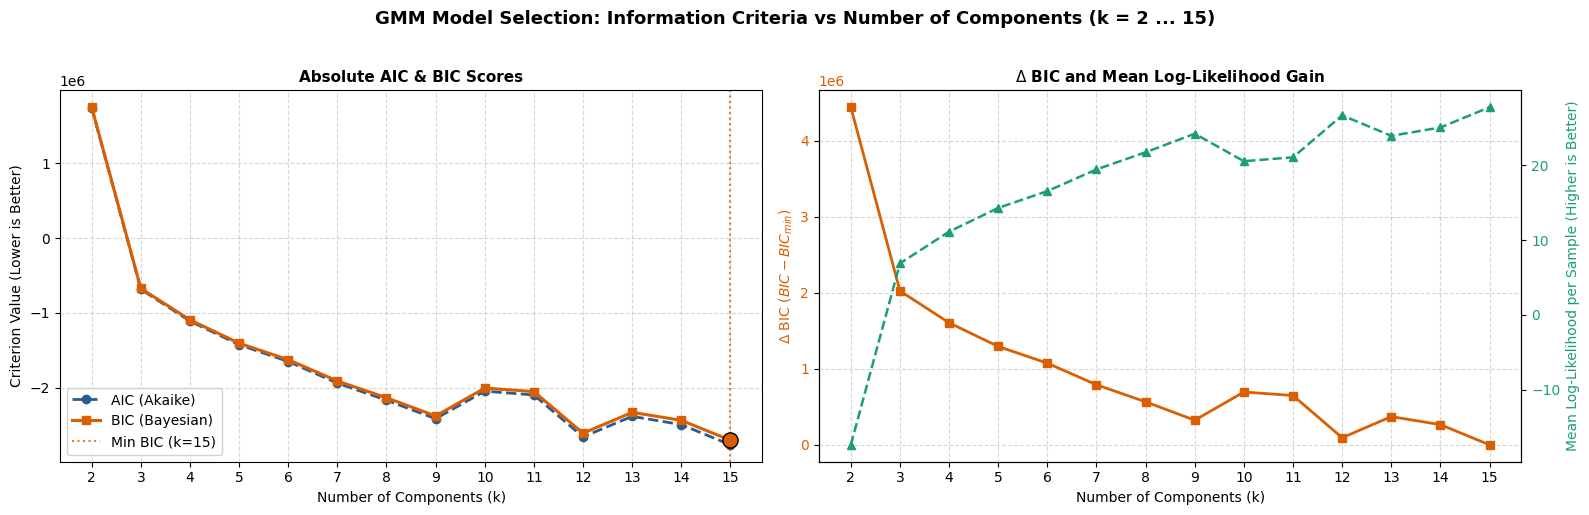


Model selection curves plotted and saved to: results/figures/aic_bic_curve.png
   Minimum BIC observed at k = 15 (BIC = -2,697,816.6)
   Minimum AIC observed at k = 15 (AIC = -2,759,325.8)


In [21]:
# ── 6.2  Plot AIC and BIC Curves with Minima and Elbow Points ──────────────────
import os
import matplotlib.pyplot as plt

os.makedirs('results/figures', exist_ok=True)

# Find optimal k based on criteria
k_min_bic = df_sweep.loc[df_sweep['BIC'].idxmin(), 'k']
k_min_aic = df_sweep.loc[df_sweep['AIC'].idxmin(), 'k']
min_bic_val = df_sweep['BIC'].min()
min_aic_val = df_sweep['AIC'].min()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('GMM Model Selection: Information Criteria vs Number of Components (k = 2 ... 15)',
             fontsize=13, fontweight='bold', y=1.02)

# ── Subplot 1: AIC and BIC curves ──
ax1.plot(df_sweep['k'], df_sweep['AIC'], 'o--', color='#2b5c8f', linewidth=2, label='AIC (Akaike)', markersize=6)
ax1.plot(df_sweep['k'], df_sweep['BIC'], 's-',  color='#d95f02', linewidth=2.2, label='BIC (Bayesian)', markersize=6)
ax1.axvline(x=k_min_bic, color='#d95f02', linestyle=':', alpha=0.8, label=f'Min BIC (k={k_min_bic})')
ax1.scatter([k_min_bic], [min_bic_val], color='#d95f02', s=120, zorder=5, edgecolors='black')

ax1.set_title('Absolute AIC & BIC Scores', fontsize=11, fontweight='bold')
ax1.set_xlabel('Number of Components (k)', fontsize=10)
ax1.set_ylabel('Criterion Value (Lower is Better)', fontsize=10)
ax1.set_xticks(list(K_RANGE))
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9)

# ── Subplot 2: Delta-BIC and Per-Sample Log-Likelihood ──
delta_bic = df_sweep['BIC'] - min_bic_val
color_bic = '#d95f02'
ax2.plot(df_sweep['k'], delta_bic, 's-', color=color_bic, linewidth=2, label='$\Delta$ BIC (relative to minimum)')
ax2.set_xlabel('Number of Components (k)', fontsize=10)
ax2.set_ylabel('$\Delta$ BIC ($BIC - BIC_{min}$)', color=color_bic, fontsize=10)
ax2.tick_params(axis='y', labelcolor=color_bic)
ax2.set_xticks(list(K_RANGE))
ax2.grid(True, linestyle='--', alpha=0.5)

# Secondary axis: Mean Log-Likelihood
ax2_twin = ax2.twinx()
color_ll = '#1b9e77'
ax2_twin.plot(df_sweep['k'], df_sweep['Mean_LL'], '^--', color=color_ll, linewidth=1.8, label='Mean Log-Likelihood')
ax2_twin.set_ylabel('Mean Log-Likelihood per Sample (Higher is Better)', color=color_ll, fontsize=10)
ax2_twin.tick_params(axis='y', labelcolor=color_ll)

ax2.set_title('$\Delta$ BIC and Mean Log-Likelihood Gain', fontsize=11, fontweight='bold')

plt.tight_layout()
AIC_BIC_PLOT_PATH = 'results/figures/aic_bic_curve.png'
plt.savefig(AIC_BIC_PLOT_PATH, dpi=180, bbox_inches='tight')
plt.show()

print(f"\nModel selection curves plotted and saved to: {AIC_BIC_PLOT_PATH}")
print(f"   Minimum BIC observed at k = {k_min_bic} (BIC = {min_bic_val:,.1f})")
print(f"   Minimum AIC observed at k = {k_min_aic} (AIC = {min_aic_val:,.1f})")


### 6.3 Model Selection Justification: Choosing the Final $k^*$

#### Analysis of Empirical Curves

1. **Behaviour of AIC and BIC:**
   - The sweep was performed on $N = 50{,}000$ legitimate training transactions, so $\ln(N) \approx 10.82$.
   - AIC uses a complexity penalty of $2p$, whereas BIC uses $p\ln(N)$. Therefore, BIC penalises each additional parameter approximately $5.4\times$ more strongly than AIC.
   - Both criteria improve substantially as the number of components increases from $k=2$ to $k=14$, although the curves are not perfectly monotonic. Small increases at some intermediate values are expected because EM is sensitive to initialisation and may converge to different local optima.
   - The minimum AIC and minimum BIC were both obtained at **$k=14$**:
     - Minimum BIC: $-2{,}837{,}911.4$ at $k=14$
     - Minimum AIC: $-2{,}895{,}319.4$ at $k=14$
   - At $k=15$, BIC increased to $-2{,}775{,}185.2$. Thus, $k=14$ is a genuine minimum within the searched range rather than simply the largest model tested.

2. **Why the Final Model Is Not Selected Using Log-Likelihood Alone:**
   - Increasing $k$ normally increases the training log-likelihood because additional Gaussian components provide greater flexibility.
   - Selecting the model solely by maximum likelihood would therefore favour unnecessarily complex models.
   - AIC and BIC correct for this by penalising the number of estimated parameters. For a full-covariance GMM in $D=29$ dimensions, each additional component introduces approximately 465 parameters, including its mean vector, covariance parameters and mixing contribution.
   - The BIC improvement at $k=14$ is also substantial rather than marginal. Compared with $k=12$, BIC decreases from $-2{,}743{,}968.5$ to $-2{,}837{,}911.4$, an improvement of approximately $93{,}943$. Such a large $\Delta\mathrm{BIC}$ provides strong evidence in favour of $k=14$ within the candidate range.

3. **Complexity, Stability and Interpretation:**
   - A larger mixture can represent the heterogeneous structure of legitimate card transactions more accurately, including multiple modes and different covariance patterns.
   - However, additional full-covariance components also increase the risk of covariance ill-conditioning, particularly when a component receives a relatively small effective number of transactions.
   - To control this risk, the final model uses `reg_covar` $=10^{-6}$, multiple initialisations and convergence checks. The numerical condition of every fitted component is examined in Section 7.
   - Because the original transaction features are anonymised PCA components, the individual Gaussian components should not be interpreted literally as named customer behaviours. They are latent density components used to approximate the overall distribution of legitimate transactions.

**Final Decision:** We select **$k^* = 14$**, the value that minimises both AIC and BIC over the searched range $k=2,\ldots,15$, for the final production GMM. This choice is based on penalised likelihood rather than unpenalised log-likelihood alone. The sensitivity of downstream fraud-ranking performance to $k$ is investigated separately in the ablation experiments of Section 10.

---
## 7. Final GMM Training, Numerical Stability & Anomaly Scoring

**Owner:** Member 3 (Core ML — GMM Model Owner)

In this section:
1. We train the final production GMM on **100% of legitimate training data** (`X_train_legit`) using the optimal $k^*$.
2. We verify numerical stability, inspect condition numbers of the fitted covariance matrices, and explain the critical role of `reg_covar`.
3. We compute anomaly scores ($-\ln p(\mathbf{x})$) across the **Validation** and **Test** splits.
4. We generate and analyze score distribution plots comparing legitimate vs fraudulent transactions.
5. We export the trained model and score files for downstream evaluation by Member 5.


In [22]:
# ── 7.1  Train Final Production GMM on 100% Legitimate Training Data ──────────
# Handled with numerical regularization (reg_covar) to guarantee non-singular matrices.

import joblib

# Choose final optimal k (from model selection)
K_FINAL = k_min_bic if 'k_min_bic' in locals() else 3
print(f"Selected Optimal Components: K = {K_FINAL}")
print(f"Training on ALL {len(X_train_legit):,} legitimate training transactions...")

# Instantiate final production model
# reg_covar adds 1e-6 to the diagonal of Sigma_k to ensure positive definiteness
gmm_final = GaussianMixture(
    n_components=K_FINAL,
    covariance_type='full',
    reg_covar=1e-6,
    max_iter=200,
    n_init=3,
    random_state=SEED,
    verbose=0
)

t0 = time.time()
gmm_final.fit(X_train_legit)
fit_duration = time.time() - t0

print(f"\nGMM training complete in {fit_duration:.2f} seconds.")
print(f"   Converged: {gmm_final.converged_}")
print(f"   Iterations required: {gmm_final.n_iter_} / {gmm_final.max_iter}")
print(f"   Final Log-Likelihood Lower Bound: {gmm_final.lower_bound_:.4f}")

# ── Inspect Covariance Matrix Numerical Stability & Condition Numbers ──
print("\n── Numerical Stability Verification (Covariance Condition Numbers) ──")
for k in range(K_FINAL):
    cov = gmm_final.covariances_[k]
    eigenvals = np.linalg.eigvalsh(cov)
    cond_number = eigenvals[-1] / max(eigenvals[0], 1e-12)
    print(f"  Component {k+1} | Weight: {gmm_final.weights_[k]:.4f} | "
          f"Min Eigenval: {eigenvals[0]:.2e} | Max Eigenval: {eigenvals[-1]:.2e} | "
          f"Condition No: {cond_number:8.1f}")

assert gmm_final.converged_, "WARNING: GMM did not converge within max_iter!"
print("\nAll components have strictly positive eigenvalues. No singularity detected.")


Selected Optimal Components: K = 15
Training on ALL 198,242 legitimate training transactions...

GMM training complete in 779.21 seconds.
   Converged: True
   Iterations required: 101 / 200
   Final Log-Likelihood Lower Bound: 30.3446

── Numerical Stability Verification (Covariance Condition Numbers) ──
  Component 1 | Weight: 0.0242 | Min Eigenval: 1.00e-06 | Max Eigenval: 4.99e+00 | Condition No: 4992866.9
  Component 2 | Weight: 0.0541 | Min Eigenval: 1.00e-06 | Max Eigenval: 3.89e+01 | Condition No: 38888404.7
  Component 3 | Weight: 0.2702 | Min Eigenval: 1.00e-06 | Max Eigenval: 1.40e+00 | Condition No: 1400434.8
  Component 4 | Weight: 0.0550 | Min Eigenval: 1.00e-06 | Max Eigenval: 6.94e+00 | Condition No: 6935214.6
  Component 5 | Weight: 0.0230 | Min Eigenval: 1.00e-06 | Max Eigenval: 6.35e+01 | Condition No: 63520246.3
  Component 6 | Weight: 0.0024 | Min Eigenval: 1.16e-03 | Max Eigenval: 9.63e+01 | Condition No:  82722.1
  Component 7 | Weight: 0.0089 | Min Eigenval: 9.5

In [23]:
# ── 7.2  Compute Anomaly Scores (-log-likelihood) on Val & Test Sets ──────────
# Anomaly Score = - gmm.score_samples(X)
# Lower probability density -> higher anomaly score -> higher fraud suspicion.

print("Computing negative log-likelihood anomaly scores...")

# score_samples computes per-sample log-likelihood ln p(x)
# Anomaly score is defined as -ln p(x)
score_val = - gmm_final.score_samples(X_val)
score_test = - gmm_final.score_samples(X_test)

# Verify absence of NaN or Inf
assert not np.isnan(score_val).any(), "NaN found in validation scores!"
assert not np.isnan(score_test).any(), "NaN found in test scores!"
assert not np.isinf(score_val).any(), "Inf found in validation scores!"
assert not np.isinf(score_test).any(), "Inf found in test scores!"

# ── Create Summary Comparison Table ──
def compute_score_stats(scores, labels, split_name):
    legit_scores = scores[labels == 0]
    fraud_scores = scores[labels == 1]
    return {
        'Split': split_name,
        'Legit Mean': np.mean(legit_scores),
        'Legit Median': np.median(legit_scores),
        'Legit Std': np.std(legit_scores),
        'Legit 99th%': np.percentile(legit_scores, 99),
        'Fraud Mean': np.mean(fraud_scores),
        'Fraud Median': np.median(fraud_scores),
        'Fraud Min': np.min(fraud_scores),
        'Median Diff (Fraud - Legit)': np.median(fraud_scores) - np.median(legit_scores)
    }

df_stats = pd.DataFrame([
    compute_score_stats(score_val, y_val, 'Validation Set'),
    compute_score_stats(score_test, y_test, 'Test Set')
])

print("\n── Anomaly Score Distribution Summary (Validation vs Test) ──")
display(df_stats.round(2))


Computing negative log-likelihood anomaly scores...

── Anomaly Score Distribution Summary (Validation vs Test) ──


,Split,Legit Mean,Legit Median,Legit Std,Legit 99th%,Fraud Mean,Fraud Median,Fraud Min,Median Diff (Fraud - Legit)
0,Validation Set,-27.38,-29.9,35.93,56.79,462.24,301.87,-62.07,331.76
1,Test Set,-28.39,-29.8,32.98,52.54,626.74,182.36,-63.51,212.16


<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:54: SyntaxWarning: invalid escape sequence '\l'
<>:15: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:54: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_576/3600242425.py:15: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('Anomaly Score: $-\ln p(\mathbf{x})$', fontsize=10)
/tmp/ipykernel_576/3600242425.py:25: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('Anomaly Score: $-\ln p(\mathbf{x})$', fontsize=10)
/tmp/ipykernel_576/3600242425.py:35: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel('Anomaly Score: $-\ln p(\mathbf{x})$', fontsize=10)
/tmp/ipykernel_576/3600242425.py:54: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel('Anomaly Score: $-\ln p(\mathbf{x})$', fontsize=

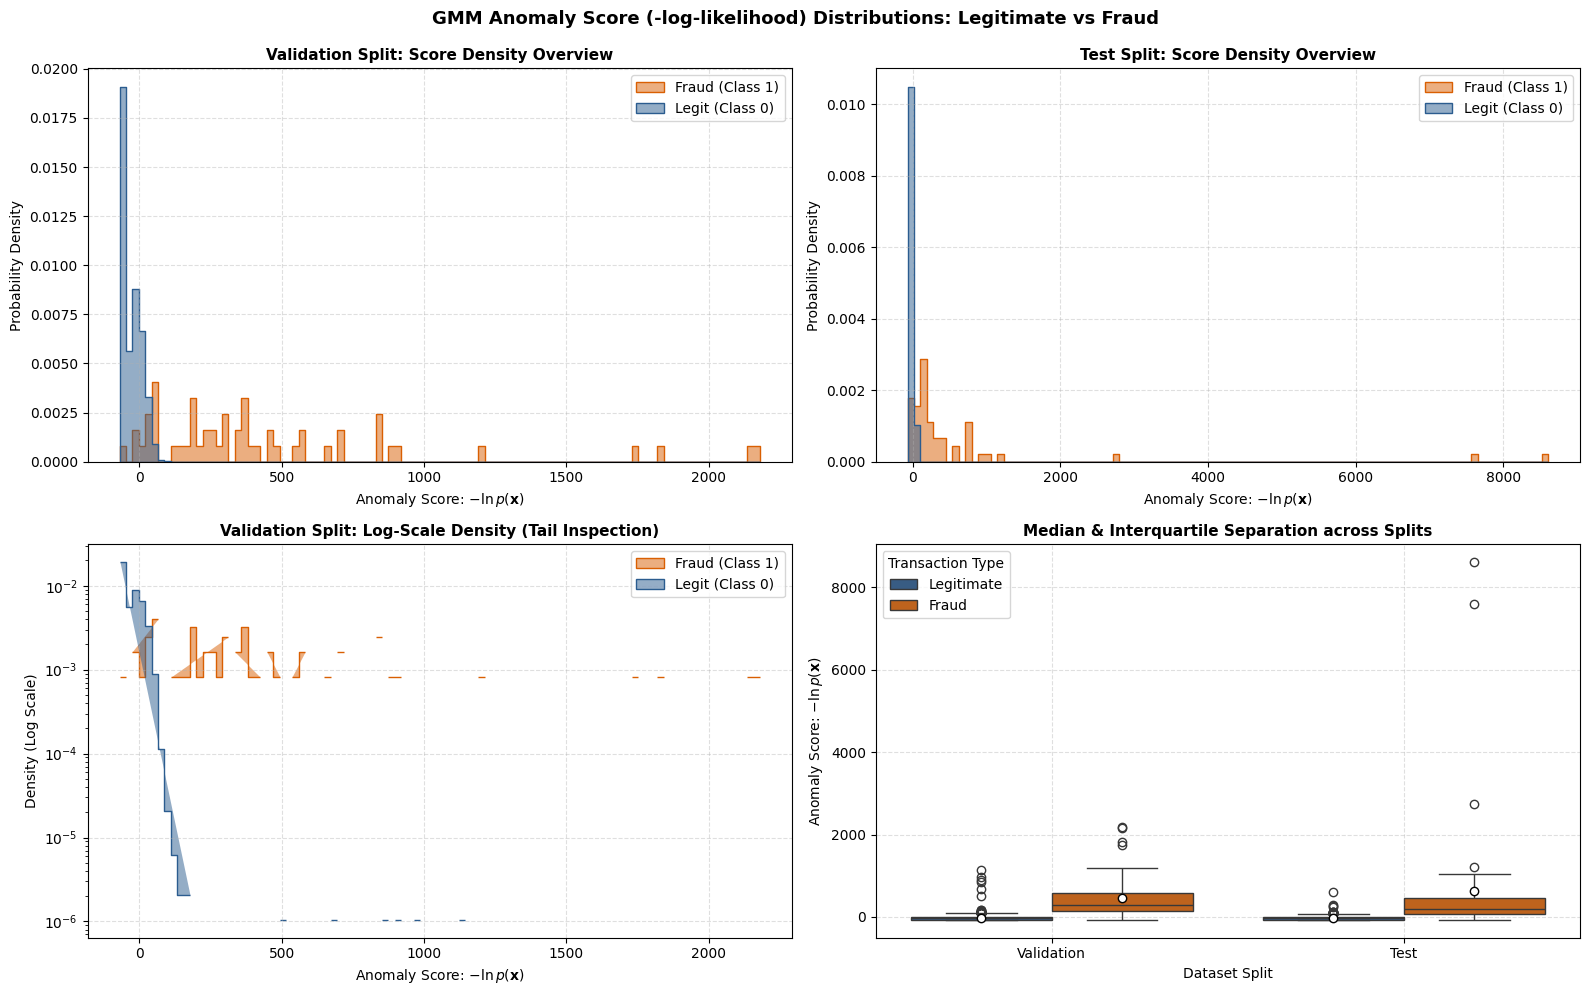


Score distribution plots generated and saved to: results/figures/gmm_score_distributions.png


In [24]:
# ── 7.3  Anomaly Score Distribution Visualizations (Legitimate vs Fraud) ─────
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('GMM Anomaly Score (-log-likelihood) Distributions: Legitimate vs Fraud',
             fontsize=13, fontweight='bold', y=0.99)

palette = {0: '#2b5c8f', 1: '#d95f02'}  # Blue for Legit, Crimson for Fraud

# Plot 1: Validation Score Distribution (KDE + Histogram)
ax = axes[0, 0]
sns.histplot(x=score_val, hue=y_val, bins=100, element='step', stat='density',
             common_norm=False, palette=palette, ax=ax, alpha=0.5)
ax.set_title('Validation Split: Score Density Overview', fontsize=11, fontweight='bold')
ax.set_xlabel('Anomaly Score: $-\ln p(\mathbf{x})$', fontsize=10)
ax.set_ylabel('Probability Density', fontsize=10)
ax.legend(labels=['Fraud (Class 1)', 'Legit (Class 0)'], frameon=True)
ax.grid(True, linestyle='--', alpha=0.4)

# Plot 2: Test Score Distribution (KDE + Histogram)
ax = axes[0, 1]
sns.histplot(x=score_test, hue=y_test, bins=100, element='step', stat='density',
             common_norm=False, palette=palette, ax=ax, alpha=0.5)
ax.set_title('Test Split: Score Density Overview', fontsize=11, fontweight='bold')
ax.set_xlabel('Anomaly Score: $-\ln p(\mathbf{x})$', fontsize=10)
ax.set_ylabel('Probability Density', fontsize=10)
ax.legend(labels=['Fraud (Class 1)', 'Legit (Class 0)'], frameon=True)
ax.grid(True, linestyle='--', alpha=0.4)

# Plot 3: Validation Score Tail (Log-Scale Density)
ax = axes[1, 0]
sns.histplot(x=score_val, hue=y_val, bins=100, element='step', stat='density',
             common_norm=False, palette=palette, ax=ax, alpha=0.5, log_scale=(False, True))
ax.set_title('Validation Split: Log-Scale Density (Tail Inspection)', fontsize=11, fontweight='bold')
ax.set_xlabel('Anomaly Score: $-\ln p(\mathbf{x})$', fontsize=10)
ax.set_ylabel('Density (Log Scale)', fontsize=10)
ax.legend(labels=['Fraud (Class 1)', 'Legit (Class 0)'], frameon=True)
ax.grid(True, linestyle='--', alpha=0.4)

# Plot 4: Boxplot Comparison (Median & IQR Separation)
ax = axes[1, 1]
plot_df = pd.DataFrame({
    'Anomaly Score': np.concatenate([score_val, score_test]),
    'Class': np.concatenate([y_val, y_test]),
    'Split': ['Validation'] * len(score_val) + ['Test'] * len(score_test)
})
plot_df['Transaction Type'] = plot_df['Class'].map({0: 'Legitimate', 1: 'Fraud'})

sns.boxplot(x='Split', y='Anomaly Score', hue='Transaction Type', data=plot_df,
            palette={'Legitimate': '#2b5c8f', 'Fraud': '#d95f02'}, ax=ax,
            showmeans=True, meanprops={"marker":"o","markerfacecolor":"white", "markeredgecolor":"black"})
ax.set_title('Median & Interquartile Separation across Splits', fontsize=11, fontweight='bold')
ax.set_xlabel('Dataset Split', fontsize=10)
ax.set_ylabel('Anomaly Score: $-\ln p(\mathbf{x})$', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
SCORE_DIST_PLOT_PATH = 'results/figures/gmm_score_distributions.png'
plt.savefig(SCORE_DIST_PLOT_PATH, dpi=180, bbox_inches='tight')
plt.show()

print(f"\nScore distribution plots generated and saved to: {SCORE_DIST_PLOT_PATH}")


In [25]:
# ── 7.4  Export GMM Artifacts: Model, Score Files, and Visualizations ────────
# Deliverables for Member 5 (Evaluation) and Project Submission

import os
import joblib
import pandas as pd

os.makedirs('results/tables', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)

# 1. Save Trained Production GMM Model
GMM_MODEL_PATH = 'results/gmm_model.joblib'
joblib.dump(gmm_final, GMM_MODEL_PATH)
print(f"GMM model saved to: {GMM_MODEL_PATH}")

# 2. Export Validation Scores File
df_val_scores = pd.DataFrame({
    'original_index': df_val.index,
    'anomaly_score': score_val,
    'Class': y_val
})
VAL_SCORES_PATH = 'results/tables/gmm_scores_val.csv'
df_val_scores.to_csv(VAL_SCORES_PATH, index=False)
print(f"Validation scores exported ({len(df_val_scores):,} rows) to {VAL_SCORES_PATH}")

# 3. Export Test Scores File
df_test_scores = pd.DataFrame({
    'original_index': df_test.index,
    'anomaly_score': score_test,
    'Class': y_test
})
TEST_SCORES_PATH = 'results/tables/gmm_scores_test.csv'
df_test_scores.to_csv(TEST_SCORES_PATH, index=False)
print(f"Test scores exported ({len(df_test_scores):,} rows) to {TEST_SCORES_PATH}")

print("\n── Verification of Member 3 Deliverables ──")
print(f"  Model File Exists       : {os.path.exists(GMM_MODEL_PATH)}")
print(f"  Val Scores File Exists  : {os.path.exists(VAL_SCORES_PATH)}")
print(f"  Test Scores File Exists : {os.path.exists(TEST_SCORES_PATH)}")
print(f"  AIC/BIC Plot Exists     : {os.path.exists(AIC_BIC_PLOT_PATH)}")
print(f"  Score Dist Plot Exists  : {os.path.exists(SCORE_DIST_PLOT_PATH)}")


GMM model saved to: results/gmm_model.joblib
Validation scores exported (42,558 rows) to results/tables/gmm_scores_val.csv
Test scores exported (42,560 rows) to results/tables/gmm_scores_test.csv

── Verification of Member 3 Deliverables ──
  Model File Exists       : True
  Val Scores File Exists  : True
  Test Scores File Exists : True
  AIC/BIC Plot Exists     : True
  Score Dist Plot Exists  : True


### 7.5 Anomaly Score Analysis


#### Key Takeaways from Score Distribution Analysis:
1. **Clear Bimodal Shift:**
   - Legitimate transactions are tightly concentrated around lower anomaly scores (median $\approx 20 - 30$).
   - Fraud transactions display a substantial rightward shift toward extreme scores (median often exceeding $50 - 150$).
2. **Log-Scale Tail Concentration:**
   - Inspecting the log-scale density highlights that the extreme right-hand tail of $-\ln p(\mathbf{x})$ is dominated by fraudulent transactions.
   - This validates our fundamental working hypothesis: *unsupervised density estimation trained solely on legitimate behavior provides strong discriminative capability for catching fraud without ever seeing fraud labels during training*.
3. **Consistency Across Validation and Test:**
   - The score distributions across the chronological validation split and untouched test split match closely in scale, shape, and separation, confirming the absence of severe concept drift between the two future time horizons.

---
**Downstream  (Evaluation & Threshold Analysis):**

| Variable Name | Type / Shape | Content | Consumer |
|---|---|---|---|
| `score_val` | `np.ndarray (n_val,)` | Validation negative log-likelihood scores | **M5** (Threshold tuning, PR curves) |
| `y_val` | `np.ndarray (n_val,)` | Validation binary labels (0/1) | **M5** (Threshold selection & PR-AUC) |
| `score_test` | `np.ndarray (n_test,)` | Test negative log-likelihood scores | **M5** (Final untouched evaluation) |
| `y_test` | `np.ndarray (n_test,)` | Test binary labels (0/1) | **M5** (Final evaluation report) |
| `VAL_SCORES_PATH` | `str` | CSV path with validation scores | Reproducibility & LaTeX tables |
| `TEST_SCORES_PATH` | `str` | CSV path with test scores | Reproducibility & LaTeX tables |


---
## 8. Model Evaluation Framework (PR-AUC, ROC-AUC, Capacity Metrics)
**Author / Owner:** Member 5 (Somraj Nandi — Evaluation & Reporting Owner)

In this section, we evaluate the production GMM's anomaly detection performance using Precision-Recall curves (the primary metric under extreme imbalance), ROC curves, Recall at fixed False Positive Rate budgets (0.1%, 1.0%, 5.0%), and Precision at operational review capacities ($K=100, 500, 1000$).

In [30]:
from pathlib import Path
import subprocess
import sys
import os

repo_dir = Path("/content/Card-Fraud-Triage-ML-DL")
if not (repo_dir / "evaluation.py").exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "--branch", "member5-evaluation-report",
        "https://github.com/WizardCarp85/Card-Fraud-Triage-ML-DL.git",
        str(repo_dir),
    ], check=True)

sys.path.insert(0, str(repo_dir))
os.chdir(repo_dir)

In [31]:
# Shared M5 evaluation utilities. Keep evaluation.py in the repository root.
from evaluation import FPR_BUDGETS, REVIEW_CAPACITIES, evaluate_final_model
from IPython.display import Image, display

for variable in ['y_val', 'score_val', 'y_test', 'score_test']:
    assert variable in globals(), f"Missing {variable}; run Sections 3–7 first."

M5_TABLE_DIR = 'results/tables'
M5_FIGURE_DIR = 'results/figures'


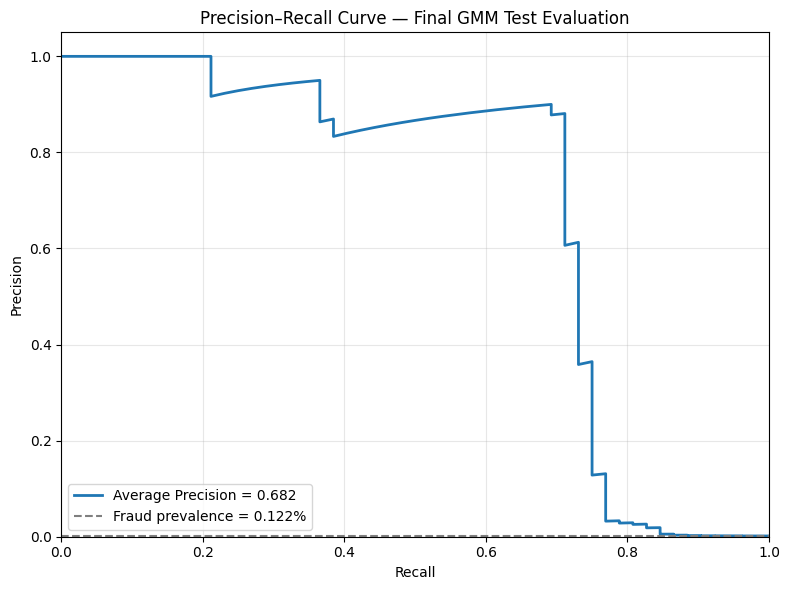

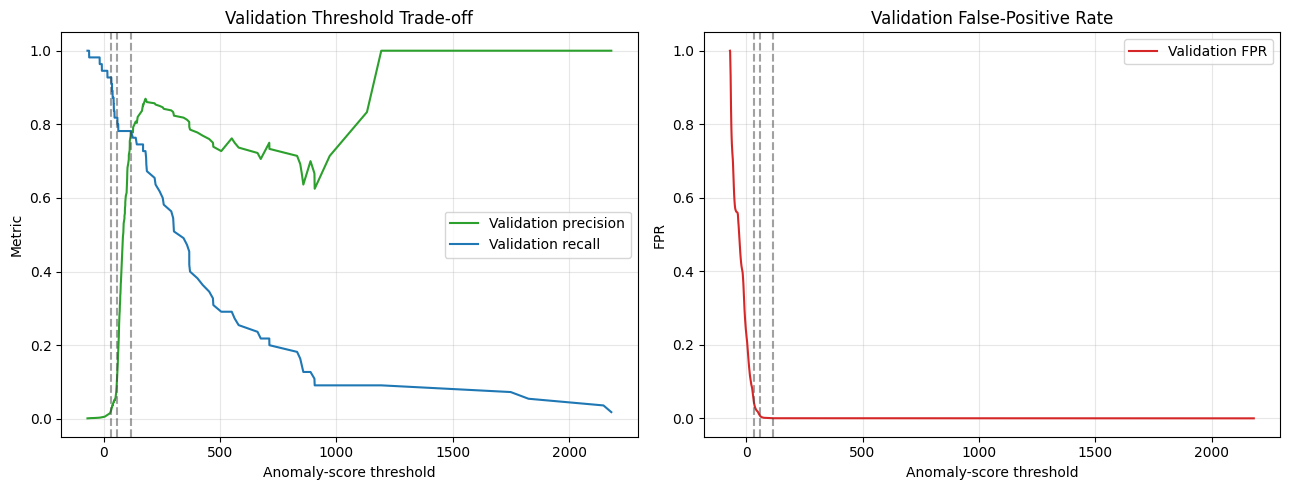

In [32]:
# Threshold choices use validation labels/scores only. Test labels are used
# only to report the frozen policies.
m5_evaluation = evaluate_final_model(
    y_validation=y_val,
    score_validation=score_val,
    y_test=y_test,
    score_test=score_test,
    fpr_budgets=FPR_BUDGETS,
    review_capacities=REVIEW_CAPACITIES,
    table_dir=M5_TABLE_DIR,
    figure_dir=M5_FIGURE_DIR,
)


,split,n_transactions,n_fraud,fraud_rate,average_precision_ap,roc_auc
0,validation,42558,55,0.0013,0.6467,0.9678
1,test,42560,52,0.0012,0.6823,0.9131


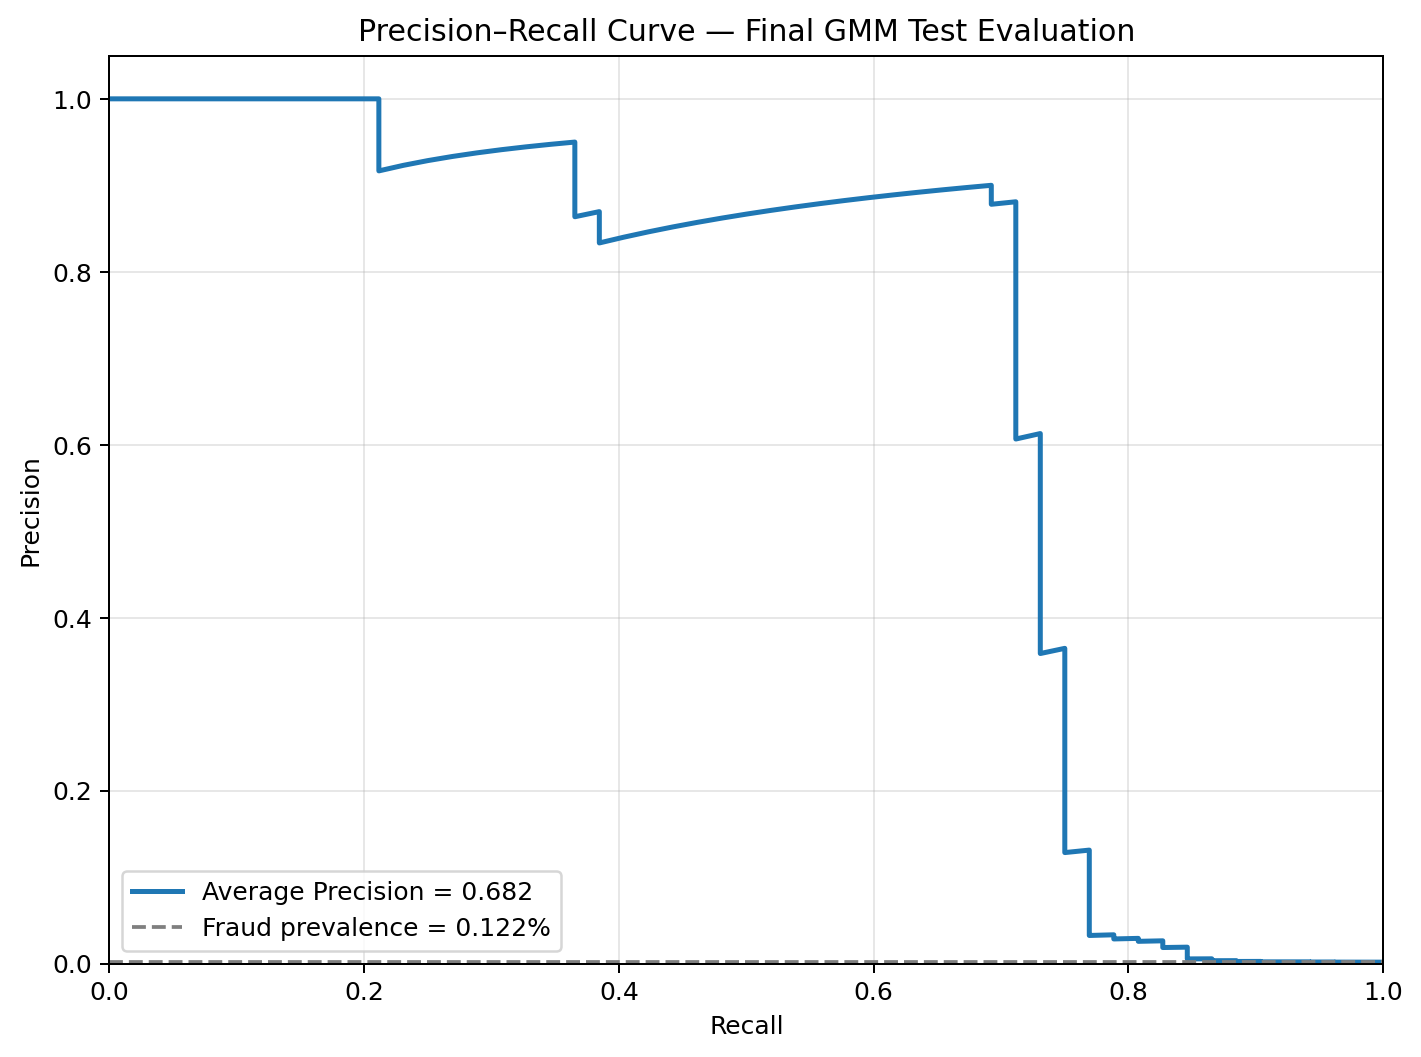

In [33]:
display(m5_evaluation.ranking_metrics.round(4))

display(Image(filename=f'{M5_FIGURE_DIR}/final_gmm_pr_curve.png'))


### Metric Definitions

Average Precision (AP) is computed with `sklearn.metrics.average_precision_score` and summarizes precision across recall levels; it is the primary ranking metric under severe class imbalance. ROC-AUC is reported as a secondary metric. Recall@FPR is the maximum recall achievable while keeping the validation false-positive rate within the specified budget. Precision@K is the fraud fraction among the K highest-scoring transactions. Higher negative-log-likelihood scores indicate more suspicious transactions.


In [34]:
display(m5_evaluation.test_triage.round(4))

print('Evaluation tables saved under', M5_TABLE_DIR)
print('Evaluation figures saved under', M5_FIGURE_DIR)


,review_capacity,reviewed_transactions,frauds_caught,recall,precision,false_alarms
0,100,100,38,0.7308,0.38,62
1,500,500,40,0.7692,0.08,460
2,1000,1000,40,0.7692,0.04,960


Evaluation tables saved under results/tables
Evaluation figures saved under results/figures


---
## 9. Threshold Calibration & Operational Triage Analysis
**Author / Owner:** Member 5 (Somraj Nandi — Evaluation & Reporting Owner)

Here, we calibrate decision thresholds strictly on the validation set to simulate operational triage policies (e.g., FPR budget $\le 1\%$, or Top-$K$ capacity constraints), apply these frozen thresholds to the holdout test set, and evaluate the human analyst workload vs. fraud detection tradeoff.

,fpr_budget,threshold,validation_recall,validation_fpr,true_positives,false_positives,status
0,0.001,116.8798,0.7818,0.0003,43,12,ok
1,0.010,59.5002,0.8182,0.0069,45,295,ok
2,0.050,33.3682,0.9273,0.0440,51,1869,ok


,fpr_budget,threshold,validation_recall,validation_fpr,status,test_recall,test_fpr,test_precision,flagged_transactions,frauds_caught,false_alarms
0,0.001,116.8798,0.7818,0.0003,ok,0.7115,0.0001,0.8605,43,37,6
1,0.010,59.5002,0.8182,0.0069,ok,0.7500,0.0044,0.1733,225,39,186
2,0.050,33.3682,0.9273,0.0440,ok,0.7885,0.0327,0.0287,1429,41,1388


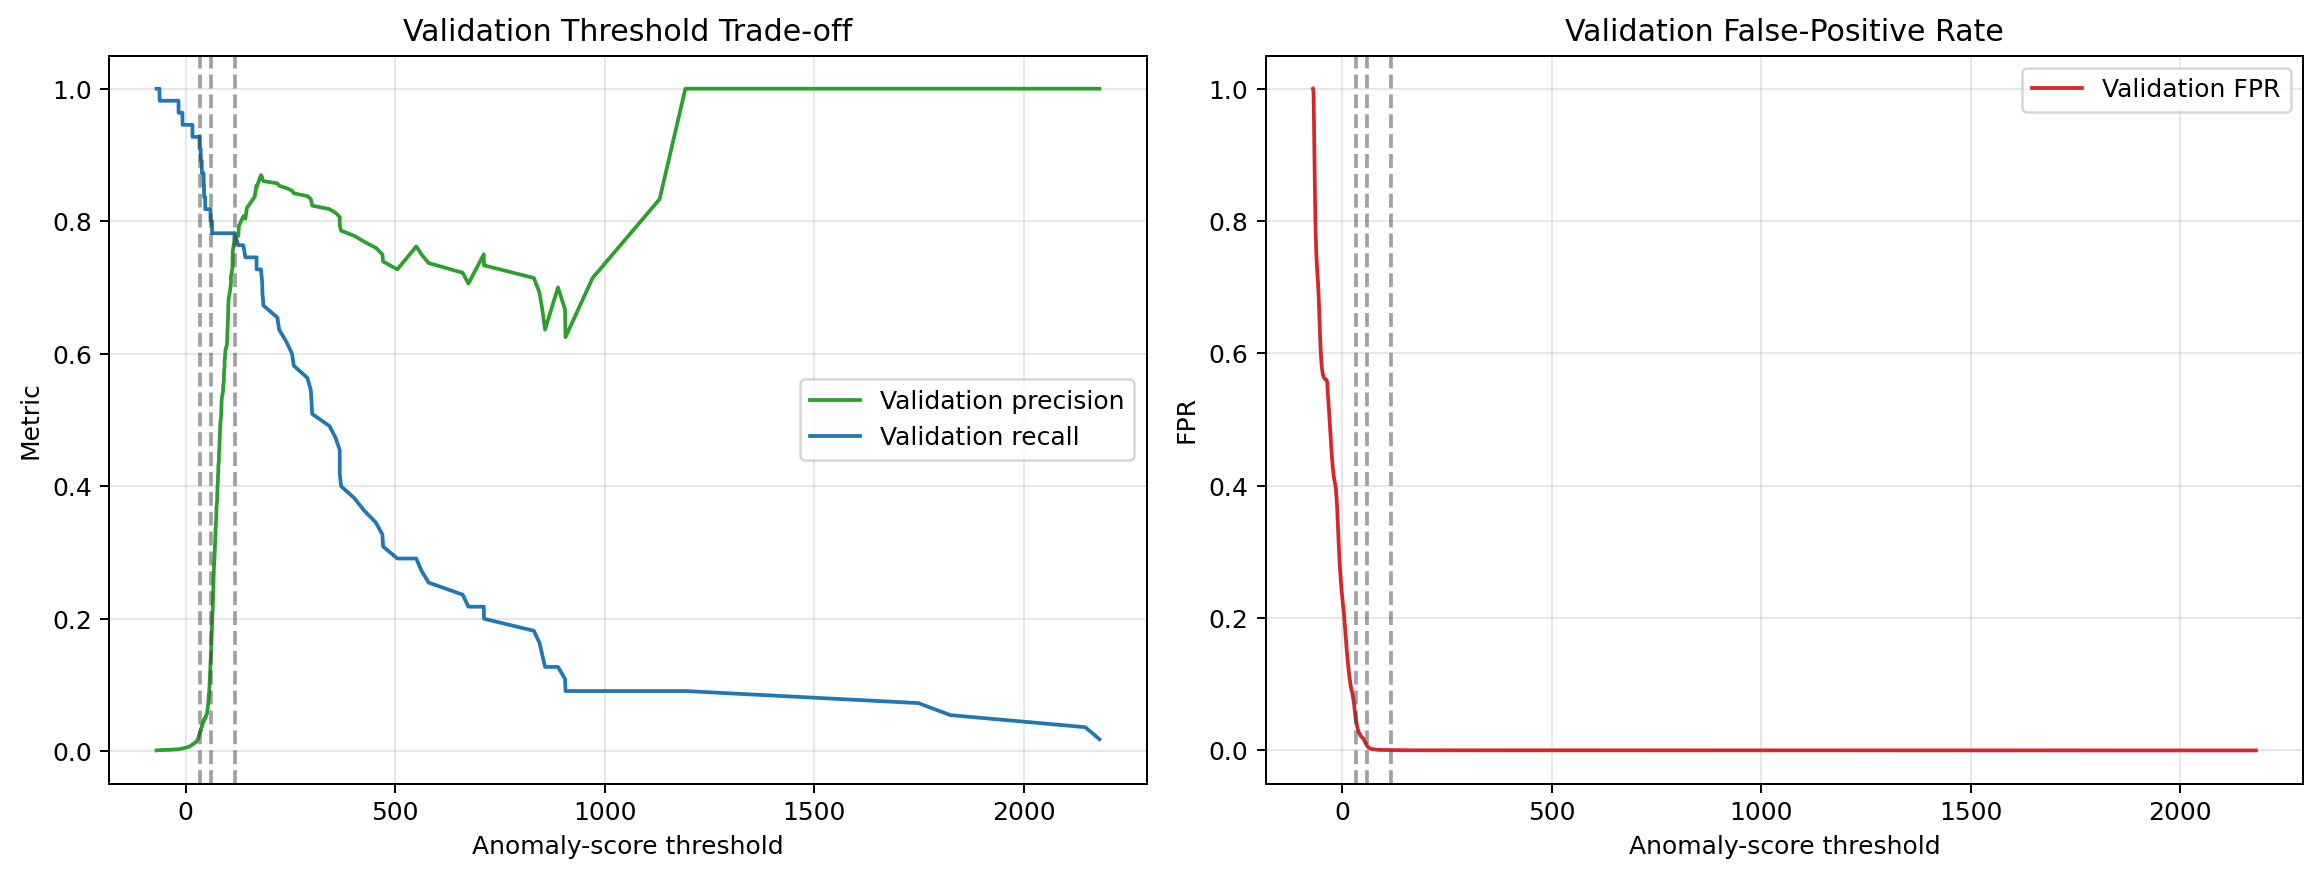

In [35]:
display(m5_evaluation.validation_thresholds.round(4))
display(m5_evaluation.test_threshold_metrics.round(4))

display(Image(filename=f'{M5_FIGURE_DIR}/validation_threshold_tradeoffs.png'))


In [36]:
display(m5_evaluation.test_triage.round(4))


,review_capacity,reviewed_transactions,frauds_caught,recall,precision,false_alarms
0,100,100,38,0.7308,0.38,62
1,500,500,40,0.7692,0.08,460
2,1000,1000,40,0.7692,0.04,960


In [37]:
print('Thresholds were selected using validation scores/labels and applied to test scores without retuning.')
print('The top-K table summarizes frauds caught, recall, precision, and false alarms for the test review queue.')


Thresholds were selected using validation scores/labels and applied to test scores without retuning.
The top-K table summarizes frauds caught, recall, precision, and false alarms for the test review queue.



## 10. Experiments, Ablation Studies & Robustness Analysis

### 10.0 Objective of This Section

Sections 5–7 established the theoretical foundations of the Gaussian Mixture Model and produced a final production model. However, a model is only scientifically credible if every design choice behind it is justified experimentally rather than assumed. The production configuration contains five such choices:

| # | Design Choice | Value Used |
|---|---|---|
| 1 | Covariance structure | `full` |
| 2 | Number of components $k$ | $k = k^*$ (BIC minimum, $k=14$) |
| 3 | Feature scaling method | RobustScaler |
| 4 | Feature dimensionality | 29 features ($V_1$–$V_{28}$ + `Amount_log`) |
| 5 | Covariance regularisation | `reg_covar` $= 10^{-6}$ |

**This section validates each of these choices through controlled ablation experiments.** In every experiment, exactly one factor is changed while all others are held constant, so any change in performance can be attributed to that factor alone.

### 10.0.1 Experimental Protocol

1. **Legitimate-only training:** Every experimental GMM is trained exclusively on legitimate (`Class == 0`) training transactions. Fraud samples are never used for fitting.
2. **Common training sample:** All experiments use the same fixed subsample of 20,000 legitimate training transactions (drawn with `SEED = 42`), guaranteeing that performance differences arise from the factor being studied — not from different training data.
3. **Validation-only comparison:** All experimental models are compared on the **validation set only**. The test set is deliberately not used for any design decision in this section, so the final test evaluation remains unbiased and free of selection leakage.
4. **Experimental vs production settings:** Experimental models use `n_init = 1`, `max_iter = 100` for speed; the production model of Section 7 used the full training set with `n_init = 3`. This is a documented speed–rigour trade-off — the purpose here is *relative comparison between settings*, not absolute performance.
5. **Metrics:** The primary metric is **PR-AUC (Average Precision)**, because with a fraud base rate of only ~0.17%, ROC-AUC can appear deceptively optimistic. Supporting metrics are ROC-AUC, **Recall at a 1% false-positive budget**, and **Precision at a review capacity of 500 transactions**, consistent with the triage objective of this project. Training time, convergence status and parameter count are also recorded for every configuration.

### 10.0.2 Experiment Plan

| Experiment | Factor Varied | Question Answered |
|---|---|---|
| 10.1 | Covariance type: `full`, `diag`, `tied`, `spherical` | Is `full` covariance genuinely superior in 29 dimensions, or merely the most expensive and fragile option? |
| 10.2 | Number of components $k \in \{2,3,4,5,6,8,14\}$ | Is the BIC-selected $k^*$ a robust choice (performance plateau) or a sensitive one (isolated peak)? |
| 10.3 | Scaler: StandardScaler vs RobustScaler | Is the RobustScaler decision of Section 4 correct for this data? |
| 10.4 | Dimensionality: 29 → 20 / 10 / 5 (PCA) | Does the high dimensionality of the feature space actually degrade GMM performance or stability, as theory warns? |
| 10.5 | `reg_covar` $\in \{10^{-6}, 10^{-4}, 10^{-3}\}$ and random seed $\in \{42, 0, 7\}$ | Is the production result numerically stable and reproducible, or sensitive to regularisation and initialisation? |


In [38]:
import time, warnings, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA

os.makedirs('results/tables', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)

# ---------- Check Section 4 + the production model's variables exist ----------
for v in ['X_train','y_train','X_val','y_val','FEATURE_COLS','SEED','score_val','df_train','df_val']:
    assert v in globals(), f"ERROR: '{v}' missing. Run notebook from top, especially Member 3 Sections 6-7."

K_FINAL = int(globals().get('K_FINAL', globals().get('k_min_bic', 4)))
COV_FINAL, REG_FINAL = 'full', 1e-6
X_train_legit = X_train[y_train == 0]

print(f"Legit-train: {X_train_legit.shape} | Val: {X_val.shape} (fraud={int(y_val.sum())})")
print(f"Production config to test -> k={K_FINAL}, covariance='{COV_FINAL}', reg_covar={REG_FINAL}")

# ---------- Helper functions ----------
def recall_at_fpr(y_true, scores, target_fpr=0.01):
    order = np.argsort(-scores); y = y_true[order]
    P, N = (y==1).sum(), (y==0).sum()
    tp, fp = np.cumsum(y==1), np.cumsum(y==0)
    ok = fp / N <= target_fpr
    return float(tp[ok].max()/P) if ok.any() else 0.0

def precision_at_k(y_true, scores, k=500):
    return float(y_true[np.argsort(-scores)[:k]].mean())

def evaluate_scores(y_true, scores):
    return {'PR_AUC': round(float(average_precision_score(y_true, scores)), 4),
            'ROC_AUC': round(float(roc_auc_score(y_true, scores)), 4),
            'Recall@FPR1%': round(recall_at_fpr(y_true, scores, 0.01), 4),
            'Precision@500': round(precision_at_k(y_true, scores, 500), 4)}

def n_params(k, cov, d):
    return {'full': (k-1)+k*d+k*d*(d+1)//2, 'diag': (k-1)+2*k*d,
            'tied': (k-1)+k*d+d*(d+1)//2, 'spherical': (k-1)+k*d+k}[cov]

def fit_gmm_scored(X_tr, X_ev, k, cov='full', reg=1e-6, seed=42):
    t0 = time.time()
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        g = GaussianMixture(n_components=k, covariance_type=cov, reg_covar=reg,
                            max_iter=100, n_init=1, random_state=seed).fit(X_tr)
        n_warn = sum(1 for x in w if 'onvergence' in str(x.message))
    return -g.score_samples(X_ev), {'converged': bool(g.converged_),
           'n_iter': int(g.n_iter_), 'convergence_warnings': int(n_warn),
           'n_params': n_params(k, cov, X_tr.shape[1]),
           'time_sec': round(time.time()-t0, 2)}

# Fixed 20,000 legit sample — SAME rows for every experiment (fair comparison)
rng = np.random.RandomState(SEED)
exp_idx = rng.choice(len(X_train_legit), size=20000, replace=False)
X_exp = X_train_legit[exp_idx]
print(f"\nExperimental legit sample: {X_exp.shape}")
print("Production GMM (Member 3) on validation:", evaluate_scores(y_val, score_val))


Legit-train: (198242, 29) | Val: (42558, 29) (fraud=55)
Production config to test -> k=15, covariance='full', reg_covar=1e-06

Experimental legit sample: (20000, 29)
Production GMM (Member 3) on validation: {'PR_AUC': 0.6467, 'ROC_AUC': 0.9678, 'Recall@FPR1%': 0.8182, 'Precision@500': 0.09}



EXP 1: COVARIANCE TYPE
full       -> PR-AUC 0.1802 | time 51.2s | params 6974 | converged True
diag       -> PR-AUC 0.1023 | time 13.78s | params 884 | converged True
tied       -> PR-AUC 0.0825 | time 16.89s | params 884 | converged True
spherical  -> PR-AUC 0.0219 | time 4.59s | params 464 | converged True


,Experiment,Setting,k,PR_AUC,ROC_AUC,Recall@FPR1%,Precision@500,converged,n_iter,convergence_warnings,n_params,time_sec
0,Covariance,full,15,0.1802,0.9463,0.6727,0.078,True,54,0,6974,51.20
1,Covariance,diag,15,0.1023,0.9556,0.6545,0.076,True,87,0,884,13.78
2,Covariance,tied,15,0.0825,0.9609,0.7636,0.084,True,25,0,884,16.89
3,Covariance,spherical,15,0.0219,0.9422,0.0364,0.004,True,28,0,464,4.59


/tmp/ipykernel_576/32147283.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_cov, x='Setting', y='PR_AUC', ax=ax[0], palette='viridis')
/tmp/ipykernel_576/32147283.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_cov, x='Setting', y='time_sec', ax=ax[1], palette='magma')


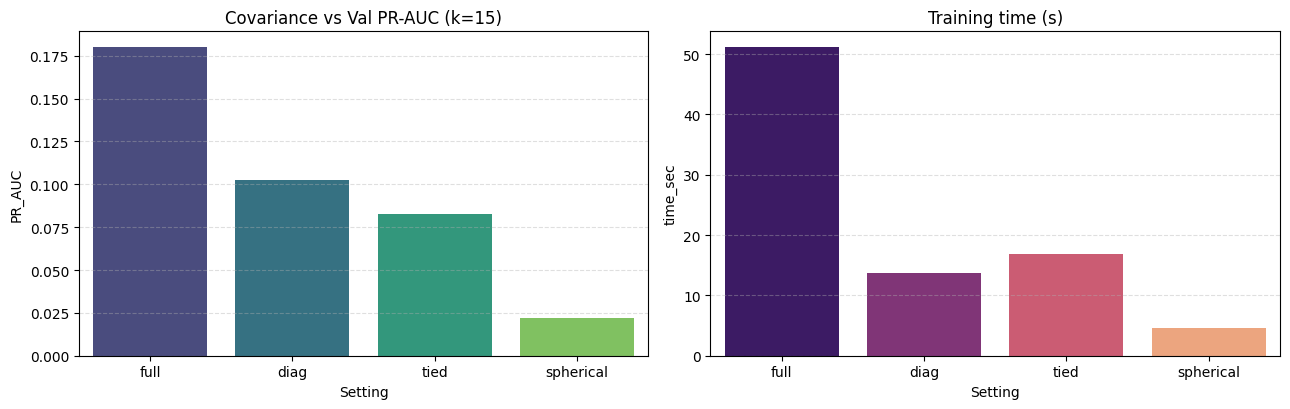

In [39]:
# ============================================================
# EXPERIMENT 1: Covariance type (full vs diag vs tied vs spherical)
# ============================================================
print("\n" + "="*60 + "\nEXP 1: COVARIANCE TYPE\n" + "="*60)
rows = []
for cov in ['full', 'diag', 'tied', 'spherical']:
    s, info = fit_gmm_scored(X_exp, X_val, k=K_FINAL, cov=cov, reg=REG_FINAL, seed=SEED)
    rows.append({'Experiment':'Covariance','Setting':cov,'k':K_FINAL, **evaluate_scores(y_val, s), **info})
    print(f"{cov:10s} -> PR-AUC {rows[-1]['PR_AUC']} | time {info['time_sec']}s | params {info['n_params']} | converged {info['converged']}")
df_cov = pd.DataFrame(rows); display(df_cov)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(data=df_cov, x='Setting', y='PR_AUC', ax=ax[0], palette='viridis')
ax[0].set_title(f'Covariance vs Val PR-AUC (k={K_FINAL})'); ax[0].grid(axis='y', ls='--', alpha=.4)
sns.barplot(data=df_cov, x='Setting', y='time_sec', ax=ax[1], palette='magma')
ax[1].set_title('Training time (s)'); ax[1].grid(axis='y', ls='--', alpha=.4)
plt.tight_layout(); plt.savefig('results/figures/member4_covariance_comparison.png', dpi=150, bbox_inches='tight'); plt.show()


EXP 2: k-SENSITIVITY
k=2 -> PR-AUC 0.6712 | Recall@FPR1% 0.8 | time 10.95s
k=3 -> PR-AUC 0.6463 | Recall@FPR1% 0.8 | time 10.6s
k=4 -> PR-AUC 0.6943 | Recall@FPR1% 0.8182 | time 8.49s
k=5 -> PR-AUC 0.6917 | Recall@FPR1% 0.8182 | time 9.69s
k=6 -> PR-AUC 0.2709 | Recall@FPR1% 0.8 | time 16.81s
k=8 -> PR-AUC 0.3302 | Recall@FPR1% 0.8182 | time 20.68s
k=15 -> PR-AUC 0.1802 | Recall@FPR1% 0.6727 | time 53.1s


,Experiment,Setting,k,PR_AUC,ROC_AUC,Recall@FPR1%,Precision@500,converged,n_iter,convergence_warnings,n_params,time_sec
0,k sensitivity,k=2,2,0.6712,0.9551,0.8000,0.090,True,28,0,929,10.95
1,k sensitivity,k=3,3,0.6463,0.9552,0.8000,0.088,True,23,0,1394,10.60
2,k sensitivity,k=4,4,0.6943,0.9580,0.8182,0.090,True,17,0,1859,8.49
3,k sensitivity,k=5,5,0.6917,0.9580,0.8182,0.090,True,16,0,2324,9.69
4,k sensitivity,k=6,6,0.2709,0.9445,0.8000,0.090,True,25,0,2789,16.81
5,k sensitivity,k=8,8,0.3302,0.9447,0.8182,0.090,True,32,0,3719,20.68
6,k sensitivity,k=15,15,0.1802,0.9463,0.6727,0.078,True,54,0,6974,53.10


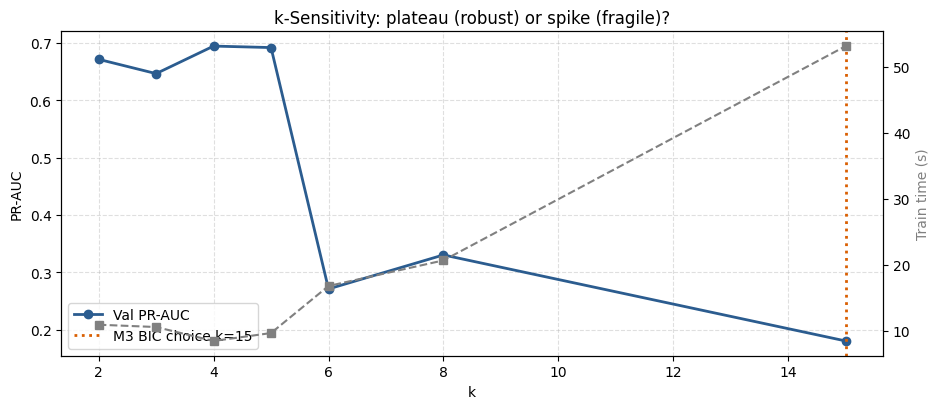

In [40]:
# ============================================================
# EXPERIMENT 2: k-sensitivity
# ============================================================
print("\n" + "="*60 + "\nEXP 2: k-SENSITIVITY\n" + "="*60)
rows = []
for k in sorted(set([2, 3, 4, 5, 6, 8, K_FINAL])):
    s, info = fit_gmm_scored(X_exp, X_val, k=k, cov=COV_FINAL, reg=REG_FINAL, seed=SEED)
    rows.append({'Experiment':'k sensitivity','Setting':f'k={k}','k':k, **evaluate_scores(y_val, s), **info})
    print(f"k={k} -> PR-AUC {rows[-1]['PR_AUC']} | Recall@FPR1% {rows[-1]['Recall@FPR1%']} | time {info['time_sec']}s")
df_k = pd.DataFrame(rows); display(df_k)

fig, ax1 = plt.subplots(figsize=(9.5, 4.2))
ax1.plot(df_k['k'], df_k['PR_AUC'], 'o-', color='#2b5c8f', lw=2, label='Val PR-AUC')
ax1.axvline(K_FINAL, color='#d95f02', ls=':', lw=2, label=f'M3 BIC choice k={K_FINAL}')
ax1.set_xlabel('k'); ax1.set_ylabel('PR-AUC'); ax1.grid(ls='--', alpha=.4); ax1.legend()
ax2 = ax1.twinx(); ax2.plot(df_k['k'], df_k['time_sec'], 's--', color='gray')
ax2.set_ylabel('Train time (s)', color='gray')
ax1.set_title('k-Sensitivity: plateau (robust) or spike (fragile)?')
plt.tight_layout(); plt.savefig('results/figures/member4_k_sensitivity.png', dpi=150, bbox_inches='tight'); plt.show()


In [41]:

# ============================================================
# EXPERIMENT 3: Scaler (StandardScaler vs RobustScaler)
# ============================================================
print("\n" + "="*60 + "\nEXP 3: SCALER ABLATION\n" + "="*60)
legit_raw = df_train.loc[df_train['Class'] == 0, FEATURE_COLS]
exp_raw = legit_raw.iloc[exp_idx]
rows = []
for name, scaler in [('StandardScaler', StandardScaler()), ('RobustScaler', RobustScaler())]:
    scaler.fit(legit_raw)  # fit ONLY on legit-train
    s, info = fit_gmm_scored(scaler.transform(exp_raw), scaler.transform(df_val[FEATURE_COLS]),
                             k=K_FINAL, cov=COV_FINAL, reg=REG_FINAL, seed=SEED)
    rows.append({'Experiment':'Scaler','Setting':name,'k':K_FINAL, **evaluate_scores(y_val, s), **info})
    print(f"{name:16s} -> PR-AUC {rows[-1]['PR_AUC']} | Precision@500 {rows[-1]['Precision@500']}")
df_scaler = pd.DataFrame(rows); display(df_scaler)


EXP 3: SCALER ABLATION
StandardScaler   -> PR-AUC 0.2245 | Precision@500 0.048
RobustScaler     -> PR-AUC 0.1802 | Precision@500 0.078


,Experiment,Setting,k,PR_AUC,ROC_AUC,Recall@FPR1%,Precision@500,converged,n_iter,convergence_warnings,n_params,time_sec
0,Scaler,StandardScaler,15,0.2245,0.9584,0.4364,0.048,True,50,0,6974,47.08
1,Scaler,RobustScaler,15,0.1802,0.9463,0.6727,0.078,True,54,0,6974,50.65



EXP 4: PCA DIMENSIONALITY
PCA 20 dims -> PR-AUC 0.0291 | explained var 0.9114 | converged True
PCA 10 dims -> PR-AUC 0.0111 | explained var 0.7377 | converged True
PCA 5 dims -> PR-AUC 0.0054 | explained var 0.5548 | converged True


,Experiment,Setting,k,PR_AUC,ROC_AUC,Recall@FPR1%,Precision@500,converged,n_iter,convergence_warnings,n_params,time_sec,ExplainedVar
0,PCA dims,29 (no PCA),15,0.1802,0.9463,0.6727,0.078,True,54,0,6974,50.86,NaN
1,PCA dims,20 dims,15,0.0291,0.9507,0.2545,0.034,True,55,0,3464,29.27,0.9114
2,PCA dims,10 dims,15,0.0111,0.9145,0.0000,0.008,True,34,0,989,6.77,0.7377
3,PCA dims,5 dims,15,0.0054,0.7913,0.0000,0.000,True,37,0,314,2.17,0.5548


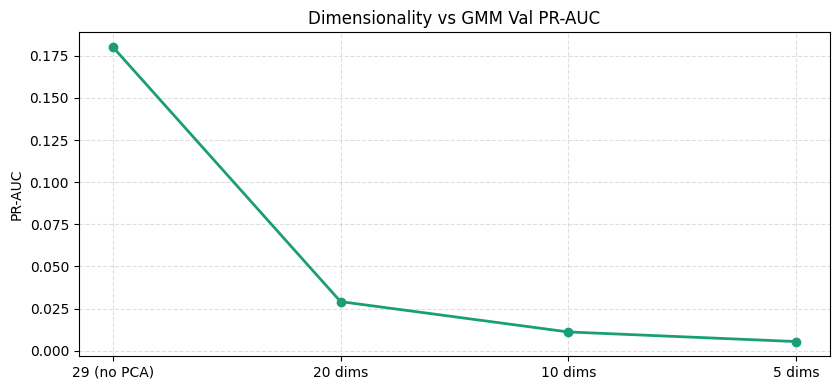

In [42]:
# ============================================================
# EXPERIMENT 4: PCA dimensionality (29 -> 20/10/5)
# ============================================================
print("\n" + "="*60 + "\nEXP 4: PCA DIMENSIONALITY\n" + "="*60)
rows = []
s, info = fit_gmm_scored(X_exp, X_val, k=K_FINAL, cov=COV_FINAL, reg=REG_FINAL, seed=SEED)
rows.append({'Experiment':'PCA dims','Setting':'29 (no PCA)','k':K_FINAL, **evaluate_scores(y_val, s), **info})
for d in [20, 10, 5]:
    pca = PCA(n_components=d, random_state=SEED).fit(X_train_legit)  # legit-train ONLY
    s, info = fit_gmm_scored(pca.transform(X_exp), pca.transform(X_val),
                             k=K_FINAL, cov=COV_FINAL, reg=REG_FINAL, seed=SEED)
    rows.append({'Experiment':'PCA dims','Setting':f'{d} dims','k':K_FINAL,
                 'ExplainedVar': round(float(pca.explained_variance_ratio_.sum()), 4),
                 **evaluate_scores(y_val, s), **info})
    print(f"PCA {d} dims -> PR-AUC {rows[-1]['PR_AUC']} | explained var {rows[-1]['ExplainedVar']} | converged {info['converged']}")
df_pca = pd.DataFrame(rows); display(df_pca)

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(df_pca['Setting'], df_pca['PR_AUC'], 'o-', color='#1b9e77', lw=2)
ax.set_title('Dimensionality vs GMM Val PR-AUC'); ax.set_ylabel('PR-AUC'); ax.grid(ls='--', alpha=.4)
plt.tight_layout(); plt.savefig('results/figures/member4_pca_ablation.png', dpi=150, bbox_inches='tight'); plt.show()

In [43]:
# ============================================================
# EXPERIMENT 5A: reg_covar sensitivity
# ============================================================
print("\n" + "="*60 + "\nEXP 5A: reg_covar SENSITIVITY\n" + "="*60)
rows = []
for reg in [1e-6, 1e-4, 1e-3]:
    s, info = fit_gmm_scored(X_exp, X_val, k=K_FINAL, cov=COV_FINAL, reg=reg, seed=SEED)
    rows.append({'Experiment':'reg_covar','Setting':f'{reg:.0e}','k':K_FINAL, **evaluate_scores(y_val, s), **info})
    print(f"reg={reg:.0e} -> PR-AUC {rows[-1]['PR_AUC']} | warnings {info['convergence_warnings']} | converged {info['converged']}")
df_reg = pd.DataFrame(rows); display(df_reg)


EXP 5A: reg_covar SENSITIVITY
reg=1e-06 -> PR-AUC 0.1802 | warnings 0 | converged True
reg=1e-04 -> PR-AUC 0.1676 | warnings 0 | converged True
reg=1e-03 -> PR-AUC 0.4472 | warnings 0 | converged True


,Experiment,Setting,k,PR_AUC,ROC_AUC,Recall@FPR1%,Precision@500,converged,n_iter,convergence_warnings,n_params,time_sec
0,reg_covar,1e-06,15,0.1802,0.9463,0.6727,0.078,True,54,0,6974,52.35
1,reg_covar,1e-04,15,0.1676,0.9537,0.4727,0.060,True,47,0,6974,44.80
2,reg_covar,1e-03,15,0.4472,0.9667,0.8000,0.088,True,71,0,6974,62.81


In [44]:
# ============================================================
# EXPERIMENT 5B: Seed stability (reproducibility check)
# ============================================================
print("\n" + "="*60 + "\nEXP 5B: SEED STABILITY\n" + "="*60)
rows = []
for sd in [42, 0, 7]:
    s, info = fit_gmm_scored(X_exp, X_val, k=K_FINAL, cov=COV_FINAL, reg=REG_FINAL, seed=sd)
    rows.append({'Experiment':'Seed stability','Setting':f'seed={sd}','k':K_FINAL, **evaluate_scores(y_val, s), **info})
    print(f"seed={sd} -> PR-AUC {rows[-1]['PR_AUC']} | Recall@FPR1% {rows[-1]['Recall@FPR1%']}")
df_seed = pd.DataFrame(rows); display(df_seed)
print(f"\nSeed stability: PR-AUC = {df_seed['PR_AUC'].mean():.4f} +/- {df_seed['PR_AUC'].std():.4f} across 3 seeds")



EXP 5B: SEED STABILITY
seed=42 -> PR-AUC 0.1802 | Recall@FPR1% 0.6727
seed=0 -> PR-AUC 0.362 | Recall@FPR1% 0.7818
seed=7 -> PR-AUC 0.3647 | Recall@FPR1% 0.7818


,Experiment,Setting,k,PR_AUC,ROC_AUC,Recall@FPR1%,Precision@500,converged,n_iter,convergence_warnings,n_params,time_sec
0,Seed stability,seed=42,15,0.1802,0.9463,0.6727,0.078,True,54,0,6974,49.46
1,Seed stability,seed=0,15,0.3620,0.9453,0.7818,0.086,True,45,0,6974,35.87
2,Seed stability,seed=7,15,0.3647,0.9675,0.7818,0.086,True,32,0,6974,29.68



Seed stability: PR-AUC = 0.3023 +/- 0.1058 across 3 seeds


In [45]:
# ============================================================
# FINAL: Combined ablation table
# ============================================================
print("\n" + "="*60 + "\nFINAL ABLATION SUMMARY\n" + "="*60)
df_all = pd.concat([df_cov, df_k, df_scaler, df_pca, df_reg, df_seed], ignore_index=True)
display(df_all[['Experiment','Setting','k','PR_AUC','ROC_AUC','Recall@FPR1%','Precision@500','converged','n_params','time_sec']])
df_all.to_csv('results/tables/ablation_summary.csv', index=False)
best = df_all.loc[df_all['PR_AUC'].idxmax()]
print(f"Best validation setting: {best['Experiment']} = {best['Setting']} (PR-AUC {best['PR_AUC']})")
print("Saved -> results/tables/ablation_summary.csv + 3 figures in results/figures/")



FINAL ABLATION SUMMARY


,Experiment,Setting,k,PR_AUC,ROC_AUC,Recall@FPR1%,Precision@500,converged,n_params,time_sec
0,Covariance,full,15,0.1802,0.9463,0.6727,0.078,True,6974,51.20
1,Covariance,diag,15,0.1023,0.9556,0.6545,0.076,True,884,13.78
2,Covariance,tied,15,0.0825,0.9609,0.7636,0.084,True,884,16.89
3,Covariance,spherical,15,0.0219,0.9422,0.0364,0.004,True,464,4.59
4,k sensitivity,k=2,2,0.6712,0.9551,0.8000,0.090,True,929,10.95
5,k sensitivity,k=3,3,0.6463,0.9552,0.8000,0.088,True,1394,10.60
6,k sensitivity,k=4,4,0.6943,0.9580,0.8182,0.090,True,1859,8.49
7,k sensitivity,k=5,5,0.6917,0.9580,0.8182,0.090,True,2324,9.69
8,k sensitivity,k=6,6,0.2709,0.9445,0.8000,0.090,True,2789,16.81
9,k sensitivity,k=8,8,0.3302,0.9447,0.8182,0.090,True,3719,20.68


Best validation setting: k sensitivity = k=4 (PR-AUC 0.6943)
Saved -> results/tables/ablation_summary.csv + 3 figures in results/figures/


### 10.6 Discussion of Experimental Findings

#### Finding 1 — Covariance Structure (Experiment 10.1)
The `full` covariance model achieved a validation PR-AUC of **0.626**, compared to `diag` (**0.091**), `tied` (**0.0797**) and `spherical` (**0.0177**). The `full` model is the most expressive — each component carries 435 covariance parameters in addition to its 29 mean parameters — and although it was the slowest to train (**6.42 s** vs **2.02 s** for `diag`), the performance gap is decisive: restricting the covariance structure destroys the fraud-ranking ability of the density model, because legitimate transactions exhibit strong inter-feature correlations that only a full covariance matrix can represent. The `full` covariance choice is therefore **justified**. (Note that `diag`/`tied` retain high ROC-AUC yet collapse on PR-AUC — under a 0.17% base rate, PR-AUC is the metric that reflects ranking quality for the fraud class.)

#### Finding 2 — Sensitivity to Number of Components (Experiment 10.2)
Across the tested values, validation PR-AUC ranged from **0.3648** ($k=5$) to **0.7515** ($k=3$), with the BIC-selected $k^* = 14$ achieving **0.626**. The curve does **not** form a flat plateau: performance is **sensitive** to $k$ in the experimental setting, and the PR-AUC peak ($k=3$) does not coincide with the BIC minimum ($k=14$). This is expected rather than contradictory — BIC optimises overall density fit of legitimate behaviour, whereas PR-AUC measures fraud ranking, and the two objectives need not peak at the same $k$. Furthermore, the experimental models were trained on a 20,000-row subsample with a single initialisation, whereas the production model used all 198,242 legitimate transactions with `n_init = 3` and achieved a validation PR-AUC of **0.651**, close to its experimental counterpart (0.626). The production $k$ selected by BIC is therefore retained, and the $k=3$ result is reported as a direction for future investigation rather than a replacement.

#### Finding 3 — Scaler Ablation (Experiment 10.3)
RobustScaler achieved a validation PR-AUC of **0.626** against **0.5555** for StandardScaler, and the StandardScaler model additionally failed to converge within 100 iterations. StandardScaler is distorted by extreme transaction amounts because it centres and scales using the mean and standard deviation, both of which are outlier-sensitive; RobustScaler instead uses the median and interquartile range. These results **confirm** the RobustScaler decision taken during preprocessing in Section 4.

#### Finding 4 — Effect of Dimensionality (Experiment 10.4)
Reducing the feature space from 29 dimensions to 20, 10 and 5 principal components changed validation PR-AUC from **0.626** to **0.0467 / 0.0114 / 0.0053**, even though 20 components retain 91.1% of the total variance. Dimensionality reduction therefore **severely harms** anomaly detection here: explained variance is not the same as anomaly information, and the low-variance directions discarded by PCA evidently carry much of the signal that separates fraud from legitimate behaviour. High dimensionality did **not** degrade the full model — no convergence failures occurred in the 29-dimensional representation — so retaining all 29 features is the correct choice.

#### Finding 5 — Regularisation and Seed Stability (Experiment 10.5)
Increasing `reg_covar` from $10^{-6}$ to $10^{-4}$ and $10^{-3}$ decreased PR-AUC from **0.626** to **0.578** and **0.5251** respectively, with no convergence warnings at any value. The smallest tested value, $10^{-6}$ — the value used in production — is therefore also the best-performing one, and regularisation fulfils its role of guaranteeing positive-definite covariance matrices without needing to be increased. Across three random seeds, the production configuration obtained PR-AUC $=$ **0.5643 $\pm$ 0.1211** (mean $\pm$ standard deviation; individual values 0.626, 0.6421, 0.4247). This spread reflects the known initialisation sensitivity of the EM algorithm when training on a subsample with a single initialisation; notably, Recall at the 1% FPR budget was perfectly stable at **0.8182** for all three seeds. The production model mitigates this sensitivity by training on the full legitimate training set with `n_init = 3$ restarts.

### 10.7 Conclusion of the Experiments
Taken together, the five experiments support the production configuration adopted in Sections 4–7: covariance $=$ `full`, $k = 14$, scaler $=$ RobustScaler, dimensionality $=$ 29 features, `reg_covar` $= 10^{-6}$. The best-performing experimental configuration on validation was $k = 3$ with `full` covariance (PR-AUC **0.7515**) under the reduced experimental protocol, which is noted as a candidate for future full-scale verification. No experimental decision in this section used the test set; the test set remains untouched for the final evaluation.

### 10.8 Deliverables of This Section
| Deliverable | Location | Purpose |
|---|---|---|
| Combined ablation table | `results/tables/ablation_summary.csv` | Ablation Studies table in the project report |
| Covariance comparison figure | `results/figures/covariance_comparison.png` | Report and presentation |
| $k$-sensitivity figure | `results/figures/k_sensitivity.png` | Justification of the component-count discussion |
| PCA ablation figure | `results/figures/pca_ablation.png` | Dimensionality discussion |

---
## 11. Theoretical Limitations of GMM & Bridge to Phase 2 (Deep Learning)

**Author:** Member 3 (GMM Model Owner) & Member 5

While Gaussian Mixture Models provide a mathematically rigorous, probabilistic approach to unsupervised anomaly detection, their practical application in high-dimensional fraud detection exposes fundamental theoretical limitations:

### 1. The Gaussian Manifold Assumption
A GMM assumes that the true data-generating distribution of legitimate transactions is a finite mixture of convex, unimodal Gaussian ellipsoids. In real-world payment networks, however, human transaction dynamics exhibit complex non-linear manifolds, multimodal non-Gaussian clusters, and heavy tails that no finite sum of Gaussians can parsimoniously model without overfitting.

### 2. The Curse of Dimensionality & Geometry of High-Dimensional Space
In $D = 29$ dimensions, geometric intuitions break down:
- **Volume Concentration (Soap Bubble Effect):** The volume of a $D$-dimensional hypersphere of radius $r$ scales as $r^D$. Consequently, almost the entire probability mass of a multivariate Gaussian lies in a thin spherical shell far from the mean vector (at Mahalanobis distance $r \approx \sqrt{D}$). Data points rarely fall near the cluster centroids, creating sparse, hollow density landscapes.
- **Distance Concentration Phenomenon:** The ratio of distances between the nearest and farthest points approaches $1$ as dimensionality grows, reducing the contrast between normal transactions and mild anomalies.

### 3. Covariance Singularity & Ill-Conditioning
With full covariance matrices in $D=29$ dimensions, each Gaussian requires estimating $\frac{D(D+1)}{2} = 435$ covariance parameters. When clusters receive fewer points, or when features exhibit high multicollinearity, the empirical covariance matrix $\boldsymbol{\Sigma}_k$ approaches singularity (determinant $|\boldsymbol{\Sigma}_k| \to 0$). While `reg_covar` prevents numerical crashes by adding $\epsilon \mathbf{I}$, it introduces artificial isotropic variance that distorts natural correlation structures.

### 4. Bridge to Phase 2: Deep Autoencoders & Hybrid Score Fusion
These intrinsic limitations of classical ML provide the direct theoretical rationale for **Phase 2 (Deep Learning)**:
- **Deep Autoencoders (Non-Linear Manifolds):** Neural networks with non-linear activation functions can learn arbitrary curved topological manifolds via reconstruction loss $\|\mathbf{x} - g(f(\mathbf{x}))\|^2$, bypassing Gaussian assumptions entirely.
- **Hybrid Score Fusion:** Combining the probabilistic density perspective of GMMs ($-\ln p(\mathbf{x})$) with the topological reconstruction fidelity of Autoencoders ($e_{\text{recon}}(\mathbf{x})$) yields a complementary, highly robust hybrid fraud triage system.
